# Settings and utilities

## Plot settings and data paths

In [ ]:
import matplotlib.pyplot as plt
from google.colab import drive
from pathlib import Path

# Set common plot font sizes
plt.rcParams.update(
    {
        "font.size": 16,
        "axes.titlesize": 18,
        "axes.labelsize": 16,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 14,
        "figure.titlesize": 18,
    }
)

# Mount Google Drive and set the dataset root
# Change DATA_ROOT here if the practice folder is renamed or moved
drive.mount("/content/drive")
DATA_ROOT = Path("/content/drive/MyDrive/PHM Practice/Datasets")
PROJECT_ROOT = DATA_ROOT.parent

Mounted at /content/drive


## Shared utility functions

In [ ]:
import numpy as np
import pandas as pd

# Purpose: format displayed numbers without changing their stored values.
# Input: value (number); spec (optional standard Python format).
# Output: formatted text; the input value remains unchanged.
# Used in: system fault diagnosis; robot fault diagnosis; Bayesian network for robot; Kalman filter;
# PMDC load-torque estimation by EKF; CMU VAH12 SOC estimation.
def format_number(value, spec=""):
    import numbers

    if not isinstance(value, numbers.Real):
        return format(value, spec)
    value = float(value)
    if spec.endswith(("e", "E", "g", "G", "%")):
        return format(value, spec)
    if 0 < abs(value) < 0.001:
        return f"{value:.3e}"
    precision = 3 if abs(value) < 10 else 2
    import re

    pattern = re.sub(r"\.\d+f$", f".{precision}f", spec) if spec else f".{precision}f"
    return format(value, pattern)

# Preserve the existing chapter-specific figure defaults
plt.rcParams.update({"figure.figsize": (10, 6), "lines.linewidth": 1.8})

# Purpose: rms to system hi.
# Input: value - RMS values; rms_min, rms_max - measured RMS bounds.
# Output: system health index on the measured 0-to-1 scale.
# Used in: robot fault diagnosis; Bayesian network for robot.
def rms_to_system_hi(value, rms_min, rms_max):
    return (np.asarray(value) - rms_min) / (rms_max - rms_min)

# Format displayed arrays and tables without modifying stored data
np.set_printoptions(formatter={"float_kind": format_number})
pd.options.display.float_format = format_number

# System fault diagnosis

## Simulation of DC motor

reproduces paper: “A Study toward Appropriate Architecture of System Health Index for Prognostic and Health Management of Complex Engineering Systems”, Lee and Choi 2017, Proceedings of the Institution of Mechanical Engineers Part O Journal of Risk and Reliability.

### Functions for DC motor dynamics

$$
J\frac{d\omega}{dt}+b\omega=k_T i-T_L=T_o
$$
$$
L\frac{di}{dt}+Ri=V-k_T\omega
$$

State vector $X = [\omega, i]^T$. Forward-Euler integration with step $dt$.

In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, HTML

# Purpose: 10 V for the first 1.5 s of every 3 s cycle; otherwise 0 V.
# Input: t.
# Output: returned np.where(phase < voltage_on_duration, V_ON, 0.0).
# Used in: system fault diagnosis.
def voltage_profile(t):
    phase = np.mod(t, cycle_duration)
    return np.where(phase < voltage_on_duration, V_ON, 0.0)

# Purpose: forward-Euler simulation of angular velocity and current.
# Input: t_end, k_T, T_L, x0, periodic_voltage.
# Output: returned (t, voltage, omega, current, torque).
# Used in: system fault diagnosis.
def simulate_motor(t_end, k_T=None, T_L=None, x0=(0.0, 0.0), periodic_voltage=True):
    if k_T is None:
        k_T = k0
    if T_L is None:
        T_L = TL0
    t = np.arange(0.0, t_end + dt, dt)
    omega = np.zeros_like(t)
    current = np.zeros_like(t)
    omega[0], current[0] = x0
    voltage = voltage_profile(t) if periodic_voltage else np.full_like(t, V_ON)
    for n in range(len(t) - 1):
        domega = (k_T * current[n] - b * omega[n] - T_L) / J
        di = (voltage[n] - R * current[n] - k_T * omega[n]) / L
        omega[n + 1] = omega[n] + dt * domega
        current[n + 1] = current[n] + dt * di
    torque = k_T * current - T_L
    return t, voltage, omega, current, torque

# Purpose: vectorized maximum output torque during one voltage_on_duration pulse.
# Input: k_T, T_L.
# Output: returned peak.
# Used in: system fault diagnosis.
def peak_torque_batch(k_T, T_L):
    k_T = np.asarray(k_T, dtype=float)
    T_L = np.asarray(T_L, dtype=float)
    omega = np.zeros_like(k_T)
    current = np.zeros_like(k_T)
    peak = np.full_like(k_T, -np.inf)
    for _ in range(int(voltage_on_duration / dt)):
        domega = (k_T * current - b * omega - T_L) / J
        di = (V_ON - R * current - k_T * omega) / L
        omega = omega + dt * domega
        current = current + dt * di
        peak = np.maximum(peak, k_T * current - T_L)
    return peak

### Response of DC motor

One cycle lasts 3 s. Input voltage is 10 V for the first 1.5 s and 0 V otherwise.

,Symbol,Value,Unit
0,R,11.200000,ohm
1,L,0.121500,H
2,J,0.022145,kg m^2
3,b,0.002953,N m s/rad
4,k_T,1.280000,N m/A
5,V,10.000000,V
6,T_L,0.050000,N m


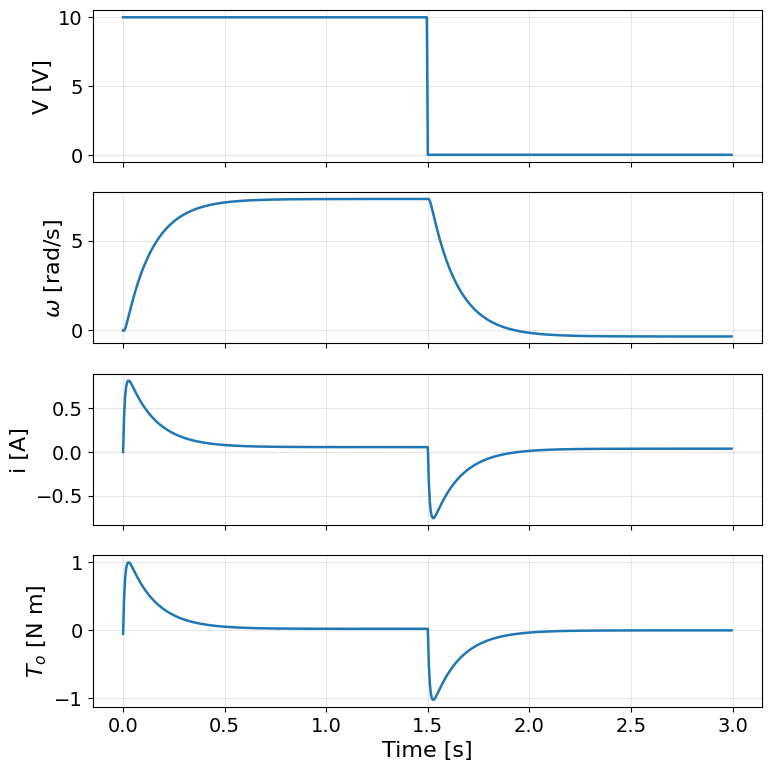

In [ ]:
# ── Dc motor parameters ──────────────────────────────────────────
R = 11.2
L = 0.1215  # Armature resistance [ohm], inductance [h]
J = 0.022145
b = 0.002953  # Inertia [kg m^2], friction [N m s/rad]
k0 = 1.28
V_ON = 10.0  # Coupling coefficient [N m/A], input voltage [V]
TL0 = 0.05  # Load torque [N m]
dt = 0.005  # Integration step [s]
cycle_duration = 3.0
voltage_on_duration = 1.5

params = pd.DataFrame(
    {
        "Symbol": ["R", "L", "J", "b", "k_T", "V", "T_L"],
        "Value": [R, L, J, b, k0, V_ON, TL0],
        "Unit": ["ohm", "H", "kg m^2", "N m s/rad", "N m/A", "V", "N m"],
    }
)
display(params)

t7, v7, w7, i7, to7 = simulate_motor(3.0 - dt)

fig, ax = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
ax[0].plot(t7, v7)
ax[0].set_ylabel("V [V]")
ax[1].plot(t7, w7)
ax[1].set_ylabel(r"$\omega$ [rad/s]")
ax[2].plot(t7, i7)
ax[2].set_ylabel("i [A]")
ax[3].plot(t7, to7)
ax[3].set_ylabel(r"$T_o$ [N m]")
ax[3].set_xlabel("Time [s]")
for axis in ax:
    axis.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Component degradation

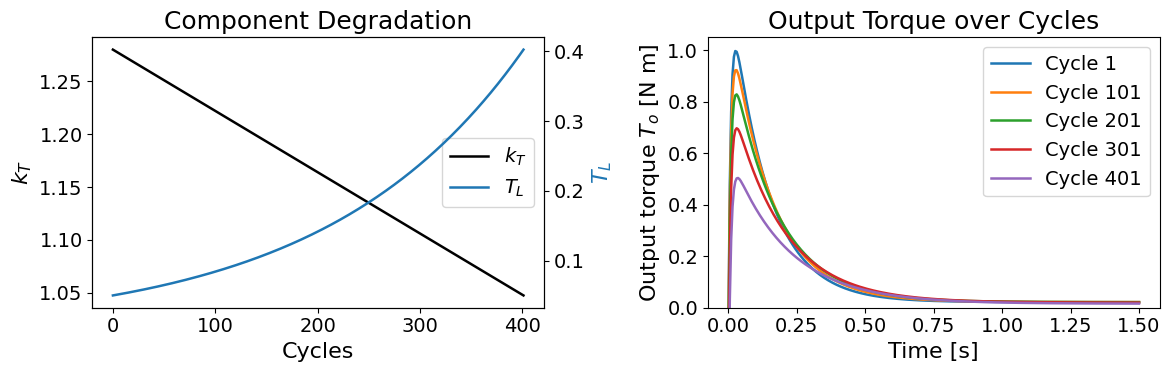

k_T at cycle 401 = 1.0475
T_L at cycle 401 = 0.4023
System performance at cycle 401 = 0.5038


In [ ]:
# Simultaneous degradation of k_T and T_L
alpha2 = -5.7974e-4
beta2 = 5.2e-3
max_cycle = 401
shown_cycles = [1, 101, 201, 301, 401]

# Purpose: health parameters.
# Input: cycles.
# Output: returned (k0 + alpha2 * cycles, TL0 * np.exp(beta2 * cycles)).
# Used in: system fault diagnosis.
def health_parameters(cycles):
    cycles = np.asarray(cycles, dtype=float)
    return k0 + alpha2 * cycles, TL0 * np.exp(beta2 * cycles)  # k_T, T_L

# Purpose: pulse torque history.
# Input: k_T, T_L.
# Output: returned (t, torque).
# Used in: system fault diagnosis.
def pulse_torque_history(k_T, T_L):
    t, _, _, _, torque = simulate_motor(
        voltage_on_duration, k_T=k_T, T_L=T_L, periodic_voltage=False
    )
    return t, torque

cycles = np.arange(max_cycle + 1)
k_curve, tl_curve = health_parameters(cycles)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Component degradation curves
ax[0].plot(cycles, k_curve, "k", label=r"$k_T$")
ax[0].set_xlabel("Cycles")
ax[0].set_ylabel(r"$k_T$")
ax[0].set_title("Component Degradation")
ax_twin = ax[0].twinx()
ax_twin.plot(cycles, tl_curve, color="tab:blue", label=r"$T_L$")
ax_twin.set_ylabel(r"$T_L$", color="tab:blue")
lines1, lbl1 = ax[0].get_legend_handles_labels()
lines2, lbl2 = ax_twin.get_legend_handles_labels()
ax[0].legend(lines1 + lines2, lbl1 + lbl2, loc="center right")

# Output-torque degradation over cycles
for cycle in shown_cycles:
    k_T, T_L = health_parameters(cycle)
    t, torque = pulse_torque_history(float(k_T), float(T_L))
    ax[1].plot(t, torque, label=f"Cycle {cycle}")
ax[1].set_xlabel("Time [s]")
ax[1].set_ylabel(r"Output torque $T_o$ [N m]")
ax[1].set_title("Output Torque over Cycles")
ax[1].set_ylim(0, 1.05)
ax[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

k_401, tl_401 = health_parameters(401)
s_401 = float(peak_torque_batch([k_401], [tl_401])[0])
print(f"k_T at cycle 401 = {format_number(k_401, '.4f')}")
print(f"T_L at cycle 401 = {format_number(tl_401, '.4f')}")
print(f"System performance at cycle 401 = {format_number(s_401, '.4f')}")

### State & health estimation by EKF

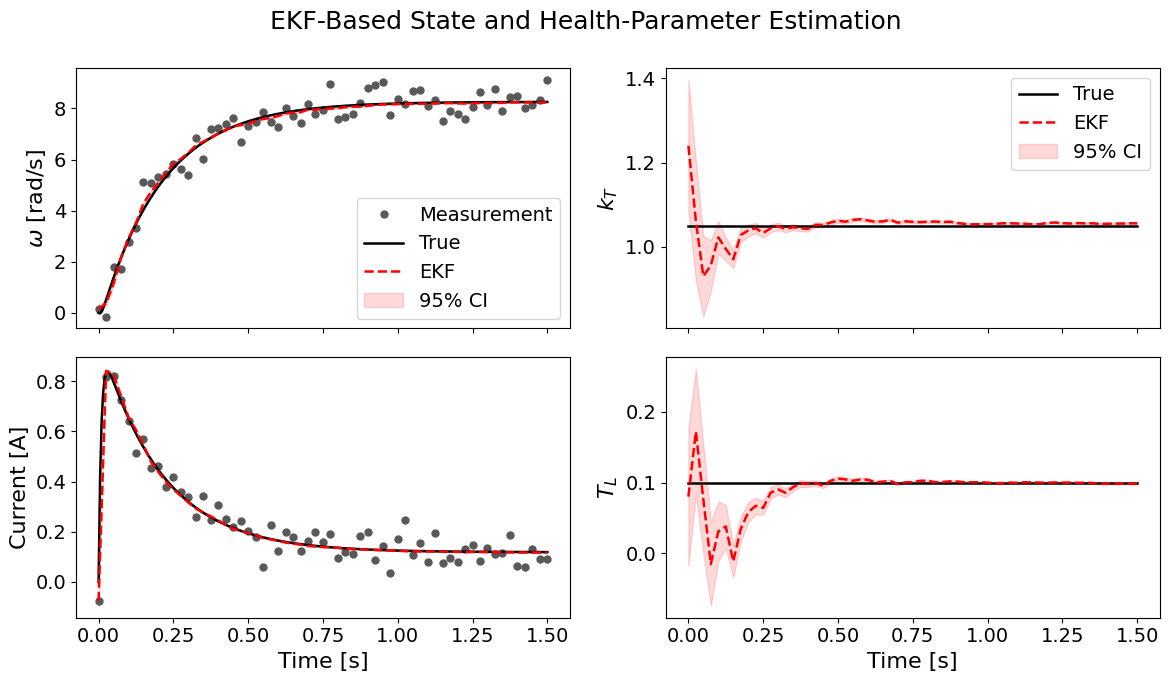

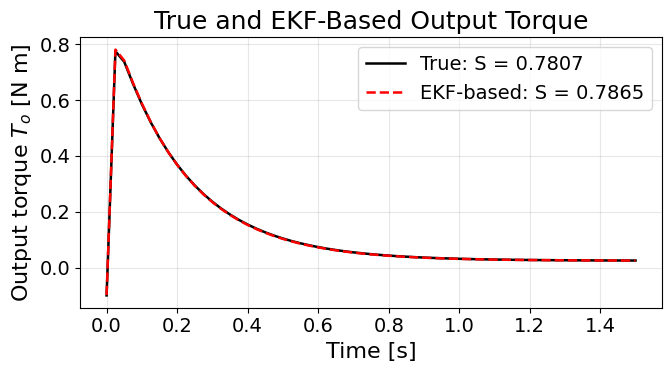

,Item,True,EKF estimate
0,k_T,1.0500,1.0555
1,T_L,0.1000,0.0983
2,System perf,0.7807,0.7865


In [ ]:
# True values used to generate virtual measurements
k_true, tl_true = 1.05, 0.10

# Purpose: state transition.
# Input: x, voltage.
# Output: computed result for the specified inputs.
# Used in: system fault diagnosis.
def state_transition(x, voltage):
    omega, current, k_T, T_L = x
    return np.array(
        [
            omega + dt * (k_T * current - b * omega - T_L) / J,
            current + dt * (voltage - R * current - k_T * omega) / L,
            k_T,
            T_L,
        ]
    )

# Purpose: transition jacobian.
# Input: x.
# Output: computed result for the specified inputs.
# Used in: system fault diagnosis.
def transition_jacobian(x):
    omega, current, k_T, _ = x
    return np.array(
        [
            [1 - dt * b / J, dt * k_T / J, dt * current / J, -dt / J],
            [-dt * k_T / L, 1 - dt * R / L, -dt * omega / L, 0],
            [0, 0, 1, 0],
            [0, 0, 0, 1],
        ]
    )

# Purpose: run ekf.
# Input: k_true, tl_true.
# Output: returned (t, z, omega_true, current_true, torque_true, x_hist, p_hist).
# Used in: system fault diagnosis.
def run_ekf(k_true, tl_true):
    t, voltage, omega_true, current_true, torque_true = simulate_motor(
        voltage_on_duration, k_T=k_true, T_L=tl_true, periodic_voltage=False
    )
    rng = np.random.default_rng(42)

    sigma_omega = 0.50
    sigma_current = 0.05

    z = np.column_stack(
        [
            omega_true + rng.normal(0, sigma_omega, len(t)),
            current_true + rng.normal(0, sigma_current, len(t)),
        ]
    )

    H = np.array([[1, 0, 0, 0], [0, 1, 0, 0]])
    Q = np.diag([1e-9, 1e-9, 1e-9, 1e-9])
    Rm = np.diag([0.10**2, 0.01**2])
    x = np.array([0.0, 0.0, 1.24, 0.08])
    P = np.diag([0.5**2, 0.1**2, 0.08**2, 0.05**2])
    x_hist = np.zeros((len(t), 4))
    p_hist = np.zeros((len(t), 4, 4))
    for n in range(len(t)):
        if n > 0:
            F = transition_jacobian(x)
            x = state_transition(x, voltage[n - 1])
            P = F @ P @ F.T + Q
        S_cov = H @ P @ H.T + Rm
        K = P @ H.T @ np.linalg.inv(S_cov)
        x = x + K @ (z[n] - H @ x)
        P = (np.eye(4) - K @ H) @ P
        x_hist[n] = x
        p_hist[n] = P
    return t, z, omega_true, current_true, torque_true, x_hist, p_hist

t, z, omega_true, current_true, torque_true, x_hist, p_hist = run_ekf(k_true, tl_true)
ci = 1.96 * np.sqrt(np.maximum(np.diagonal(p_hist, axis1=1, axis2=2), 0))
k_est, tl_est = x_hist[-1, 2:4]

# Plot state and parameter estimation
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True, dpi=100)

for row, col, true_vals, meas, ylabel, title in [
    (0, 0, omega_true, z[:, 0], r"$\omega$ [rad/s]", None),
    (1, 0, current_true, z[:, 1], "Current [A]", None),
    (0, 1, np.full(len(t), k_true), None, r"$k_T$", None),
    (1, 1, np.full(len(t), tl_true), None, r"$T_L$", None),
]:
    a = ax[row, col]
    skip = 5
    if meas is not None:
        a.plot(t[::skip], meas[::skip], ".", color="0.35", ms=10, label="Measurement")
    a.plot(t, true_vals, "k", label="True")
    idx = [[0, 2], [1, 3]][row][col]
    a.plot(t[::skip], x_hist[::skip, idx], "r--", label="EKF")
    a.fill_between(
        t[::skip],
        x_hist[::skip, idx] - ci[::skip, idx],
        x_hist[::skip, idx] + ci[::skip, idx],
        color="red",
        alpha=0.15,
        label="95% CI",
    )
    a.set_ylabel(ylabel)
    if row == 1:
        a.set_xlabel("Time [s]")

ax[0, 0].legend()
ax[0, 1].legend()
plt.suptitle("EKF-Based State and Health-Parameter Estimation")
plt.tight_layout(); plt.show()

# Output torque from EKF estimates vs true
_, _, _, _, torque_est = simulate_motor(
    voltage_on_duration, k_T=k_est, T_L=tl_est, periodic_voltage=False
)
s_true, s_est = np.max(torque_true), np.max(torque_est)

plt.figure(figsize=(7, 4))
plt.plot(
    t[::skip],
    torque_true[::skip],
    "k",
    label=f"True: S = {format_number(s_true, '.4f')}",
)
plt.plot(
    t[::skip],
    torque_est[::skip],
    "r--",
    label=f"EKF-based: S = {format_number(s_est, '.4f')}",
)
plt.xlabel("Time [s]"); plt.ylabel(r"Output torque $T_o$ [N m]")
plt.title("True and EKF-Based Output Torque"); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

display(HTML("<h4>Parameter Summary</h4>"))
display(
    pd.DataFrame(
        {
            "Item": ["k_T", "T_L", "System perf"],
            "True": [k_true, tl_true, s_true],
            "EKF estimate": [k_est, tl_est, s_est],
        }
    ).round(4)
)

### Current health and restoration

,Current,Restore k_T,Restore T_L
k_T HI,0.3508,0.0000,0.3508
T_L HI,0.0508,0.0508,0.0000
System HI,0.7050,0.1460,0.5574


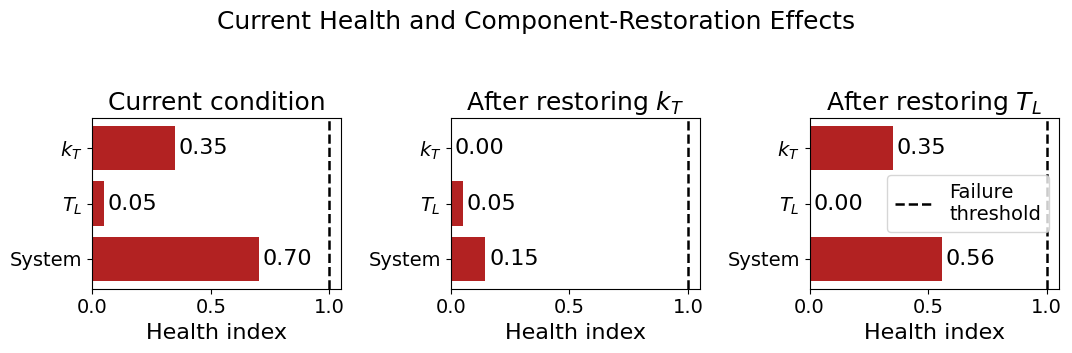

In [ ]:
# Health-index reference values
k_normal, k_fault = k0, k0 / 2
tl_normal, tl_fault = TL0, 1.0

# Use EKF estimates as the current component values
k_current, tl_current = k_est, tl_est

# Purpose: peak output torque (scalar) for the given component parameters.
# Input: k_T, T_L.
# Output: returned float(peak_torque_batch([k_T], [T_L])[0]).
# Used in: system fault diagnosis; PMDC load-torque estimation by EKF.
def performance(k_T, T_L):
    return float(peak_torque_batch([k_T], [T_L])[0])

s0 = performance(k_normal, tl_normal)  # Nominal reference

# Purpose: health indices.
# Input: k_T, T_L.
# Output: returned (np.array([hi_k, hi_tl, hi_sys]), s_ratio).
# Used in: system fault diagnosis.
def health_indices(k_T, T_L):
    s_ratio = performance(k_T, T_L) / s0
    hi_k = (k_normal - k_T) / (k_normal - k_fault)
    hi_tl = (T_L - tl_normal) / (tl_fault - tl_normal)
    hi_sys = (1 - s_ratio) / (1 - 0.7)
    return np.array([hi_k, hi_tl, hi_sys]), s_ratio

health_current, _ = health_indices(k_current, tl_current)
health_after_k, _ = health_indices(k_normal, tl_current)
health_after_tl, _ = health_indices(k_current, tl_normal)

health_summary = pd.DataFrame(
    np.vstack([health_current, health_after_k, health_after_tl]),
    index=["Current", "Restore k_T", "Restore T_L"],
    columns=["k_T HI", "T_L HI", "System HI"],
)
display(HTML("<h4>Health Summary</h4>"))
display(health_summary.T.round(4))

values_all = [health_current, health_after_k, health_after_tl]
titles = ["Current condition", r"After restoring $k_T$", r"After restoring $T_L$"]
labels = [r"$k_T$", r"$T_L$", "System"]
x_max = max(1.05, np.max(values_all) * 1.15)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.5), dpi=100, sharex=True)
for axis, values, title in zip(ax, values_all, titles):
    bars = axis.barh(labels, values, color="firebrick")
    axis.axvline(1, color="black", linestyle="--", label="Failure\nthreshold")
    axis.set_xlim(0, x_max); axis.set_xlabel("Health index"); axis.set_title(title)
    axis.invert_yaxis()
    axis.grid(False)
    for bar, value in zip(bars, values):
        axis.text(
            value + 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{format_number(value, '.2f')}",
            va="center",
        )
ax[-1].legend(loc="center right")
plt.suptitle("Current Health and Component-Restoration Effects", y=1.02)
plt.tight_layout(); plt.show()

# Robot fault diagnosis

Reproduces paper: "System-Level Fault Diagnosis for an Industrial Robot Using Bayesian Networks", Choi and Lee 2022, Proceedings of the Institution of Mechanical Engineers, Part O.

Components: Harmonic Drive (HD) and Timing Belt (TB).  
HD severity levels: Lv0 (normal) – Lv2 (most degraded).  
TB severity levels: Lv0 – Lv3.

## Functions

In [ ]:
# Purpose: fext time.
# Input: x.
# Output: computed result for the specified inputs.
# Used in: robot fault diagnosis.
def fext_time(x):
    x = np.asarray(x, dtype=float).reshape(-1)
    x_mean = np.mean(x)
    x_std = np.std(x, ddof=1)
    x_rms = np.sqrt(np.mean(x**2))
    x_sk = skew(x, bias=True)
    x_kur = kurtosis(x, fisher=False, bias=True)
    mean_abs = np.mean(np.abs(x))
    peak = np.max(np.abs(x))
    mean_sqrt_abs = np.mean(np.sqrt(np.abs(x)))
    shape_factor = x_rms / mean_abs
    crest_factor = peak / x_rms
    impulse_factor = peak / mean_abs
    margin_factor = peak / mean_sqrt_abs**2
    peak_to_peak = np.max(x) - np.min(x)
    energy = x**2
    positive_energy = energy[energy > 0]
    shannon_entropy = -np.sum(positive_energy * np.log(positive_energy))
    log_energy_entropy = np.sum(np.log(positive_energy))
    return np.array(
        [
            x_mean,
            x_std,
            x_rms,
            x_sk,
            x_kur,
            shape_factor,
            crest_factor,
            impulse_factor,
            margin_factor,
            peak,
            peak_to_peak,
            shannon_entropy,
            log_energy_entropy,
        ],
        dtype=float,
    )

# Purpose: wpd features.
# Input: x, level, wavelet.
# Output: returned (np.asarray(features, dtype=float), names).
# Used in: robot fault diagnosis.
def wpd_features(x, level=3, wavelet="db6"):
    wp = pywt.WaveletPacket(
        data=np.asarray(x, dtype=float),
        wavelet=wavelet,
        mode="symmetric",
        maxlevel=level,
    )
    nodes = wp.get_level(level, order="natural")
    features, names = [], []
    for index, node in enumerate(nodes):
        coeff = np.asarray(node.data, dtype=float)
        features.extend(fext_time(coeff))
        features.append(np.sum(coeff**2))  # Wavelet energy
        names.extend([f"W{index}-{name}" for name in TIME_FEATURE_NAMES])
        names.append(f"WE{index}")
    return np.asarray(features, dtype=float), names

# Purpose: parse raw file name.
# Input: path.
# Output: returned np.array([int(v) for v in match.groups()], dtype=np.uint8).
# Used in: robot fault diagnosis.
def parse_raw_file_name(path):
    match = RAW_FILE_PATTERN.match(path.name)
    if match is None:
        raise ValueError(f"Unexpected raw file name: {path.name}")
    return np.array([int(v) for v in match.groups()], dtype=np.uint8)

# Purpose: report model layers, parameter counts, and subset sizes.
# Input: model, training, validation, test.
# Output: printed model structure, parameter counts, and data shapes.
# Used in: robot fault diagnosis.
def show_model_info(model, training, validation, test=None):
    # Purpose: return the shapes of one or more model inputs.
    # Input: data.
    # Output: returned [tuple(value.shape) for value in values].
    def sample_shape(data):
        values = data if isinstance(data, (list, tuple)) else [data]
        return [tuple(value.shape) for value in values]

    # Purpose: return the number of samples in the model inputs.
    # Input: data.
    # Output: returned len(value).
    def sample_count(data):
        value = data[0] if isinstance(data, (list, tuple)) else data
        return len(value)

    print("Model structure")
    if hasattr(model, "summary"):
        model.summary()
        import numpy as np

        trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
        total = model.count_params()
    else:
        print(model)
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parameters: {total:,} total; {trainable:,} trainable")
    print(f"Training samples: {sample_count(training):,}")
    print(f"Validation samples: {sample_count(validation):,}")
    print("Training input shapes:", sample_shape(training))
    print("Validation input shapes:", sample_shape(validation))
    if test is not None:
        print(f"Test samples: {sample_count(test):,}")
        print("Test input shapes:", sample_shape(test))

# Purpose: create a callback that reports training and validation losses.
# Input: every.
# Output: Keras callback for progress reporting.
# Used in: robot fault diagnosis.
def training_progress(every=100):
    from tensorflow.keras.callbacks import LambdaCallback

    # Purpose: print training and validation loss at the selected epoch interval.
    # Input: epoch, logs.
    # Output: updated state or displayed result; no return value.
    def report(epoch, logs):
        if epoch == 0 or (epoch + 1) % every == 0:
            loss = format_number(logs.get("loss", float("nan")))
            valid = format_number(logs.get("val_loss", float("nan")))
            print(f"Epoch {epoch + 1}: training loss={loss}; validation loss={valid}")

    return LambdaCallback(on_epoch_end=report)

# Purpose: report completed epochs, best losses, and elapsed training time.
# Input: history, started.
# Output: printed training summary.
# Used in: robot fault diagnosis.
def report_training(history, started):
    import time
    import numpy as np

    losses = history.history
    reference = losses.get("val_loss", losses["loss"])
    best = int(np.argmin(reference))
    print(f'Completed epochs: {len(losses["loss"])}; best epoch: {best + 1}')
    print("Best training loss:", format_number(losses["loss"][best]))
    if "val_loss" in losses:
        print("Best validation loss:", format_number(losses["val_loss"][best]))
    print("Training time:", format_number(time.perf_counter() - started), "s")

## 1. Read robot data and plot representative signals

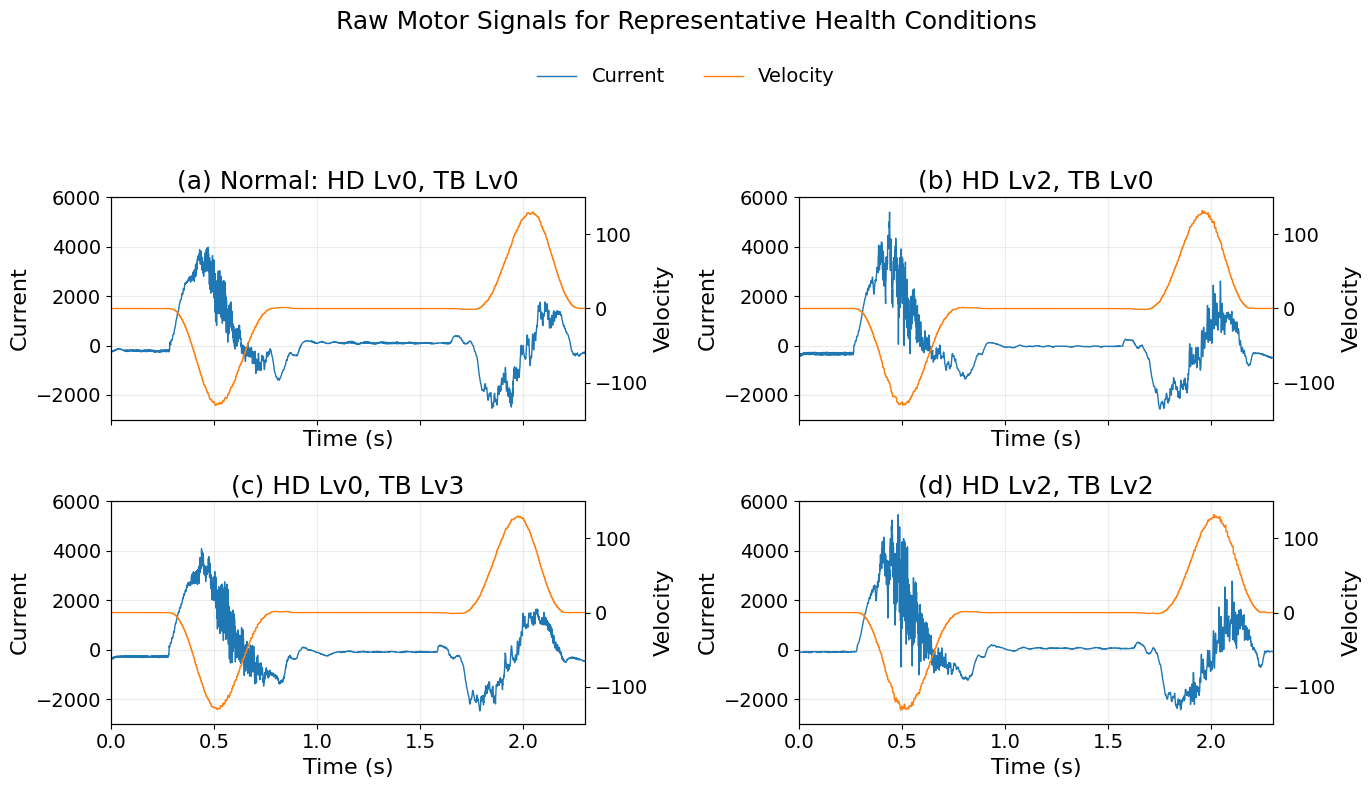

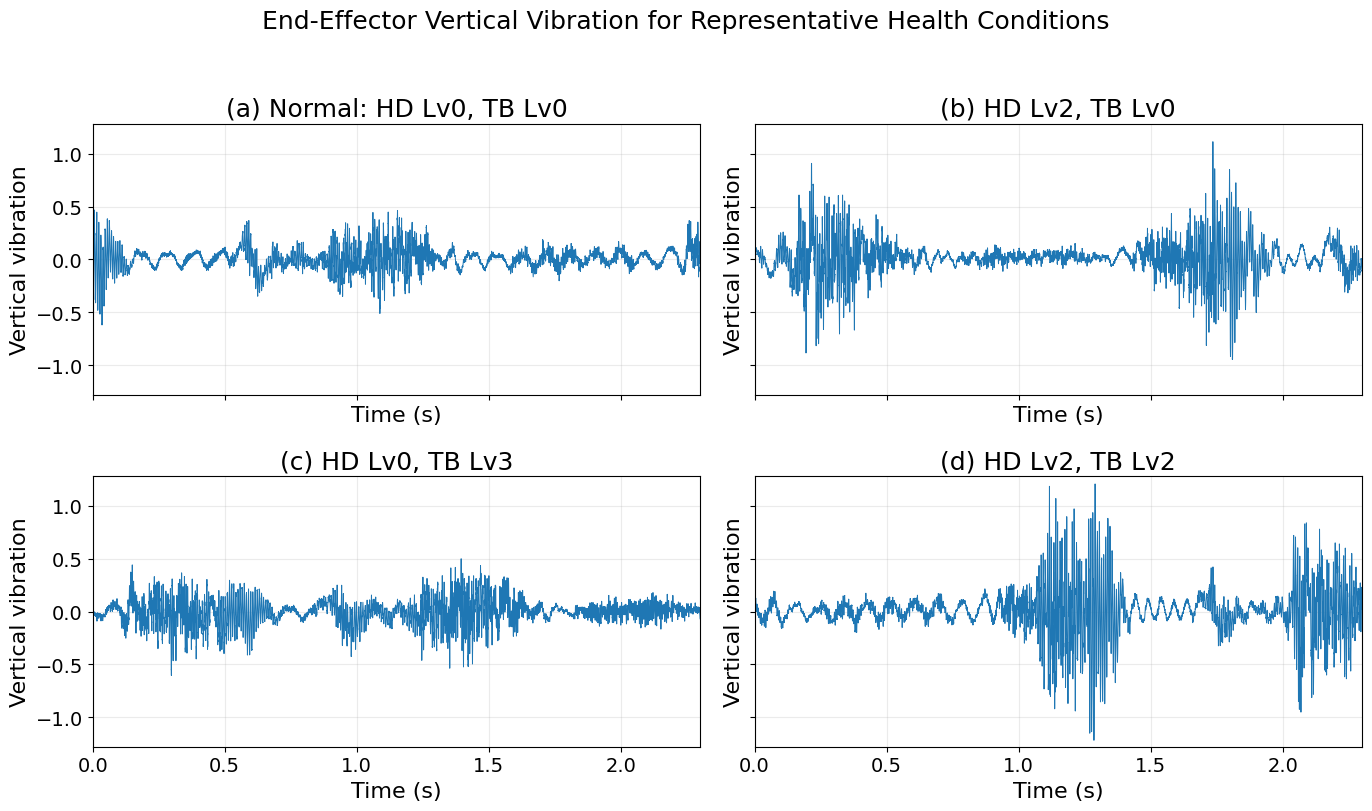

In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import re
import time
import numpy as np
import pywt
from matplotlib.lines import Line2D
from scipy.io import loadmat, savemat
from scipy.stats import skew, kurtosis

ROBOT_ROOT = DATA_ROOT / "Robot"

# Robot operation segmentation settings
FS_ROBOT = 1000  # Motor and vibration sampling frequency [Hz]
N_ROBOT = 2300  # Samples per robot operation segment
OPERATIONS_PER_FILE = 20  # Operation segments per raw .mat file
DURATION = N_ROBOT / FS_ROBOT  # 2.3 S per operation
RAW_FILE_PATTERN = re.compile(r"^(\d{2})(\d{2})_(\d{2})_(\d{2})\.mat$")

# List robot raw files and verify the expected file count
raw_files = sorted(
    path for path in ROBOT_ROOT.glob("*.mat") if RAW_FILE_PATTERN.fullmatch(path.name)
)
if len(raw_files) != 55:
    raise ValueError(f"Expected 55 raw files, but found {len(raw_files)}.")

motor_segments, operation_labels, case_data = [], [], {}
vibration_signals, vibration_sampling_rates = [], []

# Representative conditions for signal comparison
COMPARISON_CASES = [
    ("0000_00_01.mat", "Normal: HD Lv0, TB Lv0"),
    ("0000_02_01.mat", "HD Lv2, TB Lv0"),
    ("0300_00_01.mat", "HD Lv0, TB Lv3"),
    ("0200_02_01.mat", "HD Lv2, TB Lv2"),
]
comparison_names = {name for name, _ in COMPARISON_CASES}

for file_path in raw_files:

    # Read motor data, vibration signal, and vibration sampling rate from the MAT file
    data = loadmat(file_path, variable_names=["robot", "vibz", "fs"])

    # Store the complete vibration signal and its sampling rate
    vibration = np.asarray(data["vibz"], dtype=float).reshape(-1)
    fs_vib = float(np.asarray(data["fs"]).squeeze())
    vibration_signals.append(vibration)
    vibration_sampling_rates.append(fs_vib)

    # Locate robot operation boundaries using the gpl signal
    robot = np.asarray(data["robot"], dtype=float)
    rising_pts = np.where(np.diff(robot[:, 11]) == 1)[0]
    if len(rising_pts) < OPERATIONS_PER_FILE + 3:
        raise ValueError(f"{file_path.name}: insufficient GPL rising edges.")

    # Extract current and velocity segments and assign fault labels
    file_label = parse_raw_file_name(file_path)
    first_segment = None
    for operation in range(OPERATIONS_PER_FILE):
        start, stop = rising_pts[operation + 2], rising_pts[operation + 3] + 1
        segment = robot[start:stop, :]
        if len(segment) < N_ROBOT:
            raise ValueError(
                f"{file_path.name}, operation {operation + 1}: insufficient samples."
            )
        motor_segments.append(segment[:N_ROBOT, [0, 4]])
        operation_labels.append(file_label)
        if operation == 0:
            first_segment = segment[:N_ROBOT, :]

    # Keep representative motor and vibration signals for plotting
    if file_path.name in comparison_names:
        n_vib = int(DURATION * fs_vib)
        if len(vibration) < n_vib:
            raise ValueError(f"{file_path.name}: insufficient vibration samples.")
        case_data[file_path.name] = (first_segment, vibration[:n_vib], fs_vib)

vibration_sampling_rates = np.asarray(vibration_sampling_rates)
motor_segments = np.stack(motor_segments)
labseg = np.vstack(operation_labels).astype(np.uint8)
time_robot = np.arange(N_ROBOT) / FS_ROBOT
print("Raw files:", len(raw_files))
print("Motor segments:", motor_segments.shape, "(operations, samples, current/velocity)")
print()

vibration_lengths = [len(signal) for signal in vibration_signals]
print("Vibration records:", len(vibration_signals), "(files)")
print("Vibration samples per file:", min(vibration_lengths), "to", max(vibration_lengths))
print()

# Compare representative current and velocity signals
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for panel, (ax, (file_name, condition)) in enumerate(zip(axes.flat, COMPARISON_CASES)):
    segment = case_data[file_name][0]
    ax_vel = ax.twinx()
    cur_line = ax.plot(
        time_robot, segment[:, 0], color="tab:blue", lw=1, label="Current"
    )[0]
    vel_line = ax_vel.plot(
        time_robot, segment[:, 4], color="tab:orange", lw=1, label="Velocity"
    )[0]
    ax.set(
        xlim=(0, DURATION),
        ylim=(-3000, 6000),
        xlabel="Time (s)",
        ylabel="Current",
        title=f"({chr(97 + panel)}) {condition}",
    )
    ax_vel.set_ylim(-150, 150); ax_vel.set_ylabel("Velocity"); ax.grid(alpha=0.25)
fig.legend(
    [cur_line, vel_line],
    ["Current", "Velocity"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=2,
    frameon=False,
)
fig.suptitle("Raw Motor Signals for Representative Health Conditions", y=0.99)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()
print()

# Compare representative vertical vibration signals
vib_limit = 1.05 * max(np.max(np.abs(case_data[name][1])) for name, _ in COMPARISON_CASES)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for panel, (ax, (file_name, condition)) in enumerate(zip(axes.flat, COMPARISON_CASES)):
    _, vibration, fs_vib = case_data[file_name]
    ax.plot(np.arange(len(vibration)) / fs_vib, vibration, color="tab:blue", lw=0.7)
    ax.set(
        xlim=(0, DURATION),
        ylim=(-vib_limit, vib_limit),
        xlabel="Time (s)",
        ylabel="Vertical vibration",
        title=f"({chr(97 + panel)}) {condition}",
    )
    ax.grid(alpha=0.25)
fig.suptitle(
    "End-Effector Vertical Vibration for Representative Health Conditions", y=1.02
)
fig.tight_layout()
plt.show()

## 2. Extract WPD features and save.

In [ ]:
# import libraries for feature extraction, plotting, and mat-file export
import time
import numpy as np
import pywt
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.io import savemat
from scipy.stats import skew, kurtosis

# 13 Statistical feature names used by wpd_features
TIME_FEATURE_NAMES = [
    "Mean",
    "STD",
    "RMS",
    "SK",
    "KUR",
    "SF",
    "CF",
    "IF",
    "MF",
    "Peak(Max)",
    "P2P",
    "SE",
    "LEE",
]

# Extract 14 features from each WPD sub-band of current and velocity
# We is added to 13 wpd_features.
feature_rows, feature_names = [], None
start_time = time.time()

for operation, segment in enumerate(motor_segments, start=1):
    cur_feats, cur_names = wpd_features(segment[:, 0])
    vel_feats, vel_names = wpd_features(segment[:, 1])
    feature_rows.append(np.concatenate([cur_feats, vel_feats]))
    if feature_names is None:
        feature_names = [f"Cur-{name}" for name in cur_names] + [
            f"Vel-{name}" for name in vel_names
        ]
    if operation % OPERATIONS_PER_FILE == 0:
        print(
            f"{operation}/{len(motor_segments)} operations:"
            f" {format_number(time.time() - start_time, '.1f')} s"
        )

# Assemble feature arrays and report feature and label dimensions
feat_robot = np.vstack(feature_rows)
feat_name = np.asarray(feature_names, dtype=object).reshape(1, -1)
fs_r = np.array([[FS_ROBOT]], dtype=np.uint16)
print("Feature matrix:", feat_robot.shape)
print("Label matrix:", labseg.shape)

# Save the feature dataset for subsequent diagnosis
# Verify dataset dimensions before saving
expected_shapes = {
    "feat_robot": (1100, 224),
    "feat_name": (1, 224),
    "labseg": (1100, 4),
}
for name, expected in expected_shapes.items():
    actual = locals()[name].shape
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, obtained {actual}")

# Export features, feature names, sampling frequency, and labels to a MAT file
output_path = ROBOT_ROOT / "Features_robot.mat"
savemat(
    output_path,
    {"feat_robot": feat_robot, "feat_name": feat_name, "fs_r": fs_r, "labseg": labseg},
    do_compression=True,
)
print("Saved:", output_path)

20/1100 operations: 0.9 s
40/1100 operations: 1.9 s
60/1100 operations: 2.8 s
80/1100 operations: 4.2 s
100/1100 operations: 5.7 s
120/1100 operations: 7.3 s
140/1100 operations: 8.9 s
160/1100 operations: 9.9 s
180/1100 operations: 10.7 s
200/1100 operations: 11.6 s
220/1100 operations: 12.5 s
240/1100 operations: 13.5 s
260/1100 operations: 14.4 s
280/1100 operations: 15.3 s
300/1100 operations: 16.2 s
320/1100 operations: 16.8 s
340/1100 operations: 17.1 s
360/1100 operations: 17.5 s
380/1100 operations: 17.9 s
400/1100 operations: 18.3 s
420/1100 operations: 18.8 s
440/1100 operations: 19.5 s
460/1100 operations: 20.2 s
480/1100 operations: 21.0 s
500/1100 operations: 21.6 s
520/1100 operations: 22.4 s
540/1100 operations: 23.1 s
560/1100 operations: 23.7 s
580/1100 operations: 24.1 s
600/1100 operations: 24.5 s
620/1100 operations: 24.9 s
640/1100 operations: 25.3 s
660/1100 operations: 25.7 s
680/1100 operations: 26.0 s
700/1100 operations: 26.4 s
720/1100 operations: 26.8 s
740/

### Plot WPD coefficients and wavelet energy

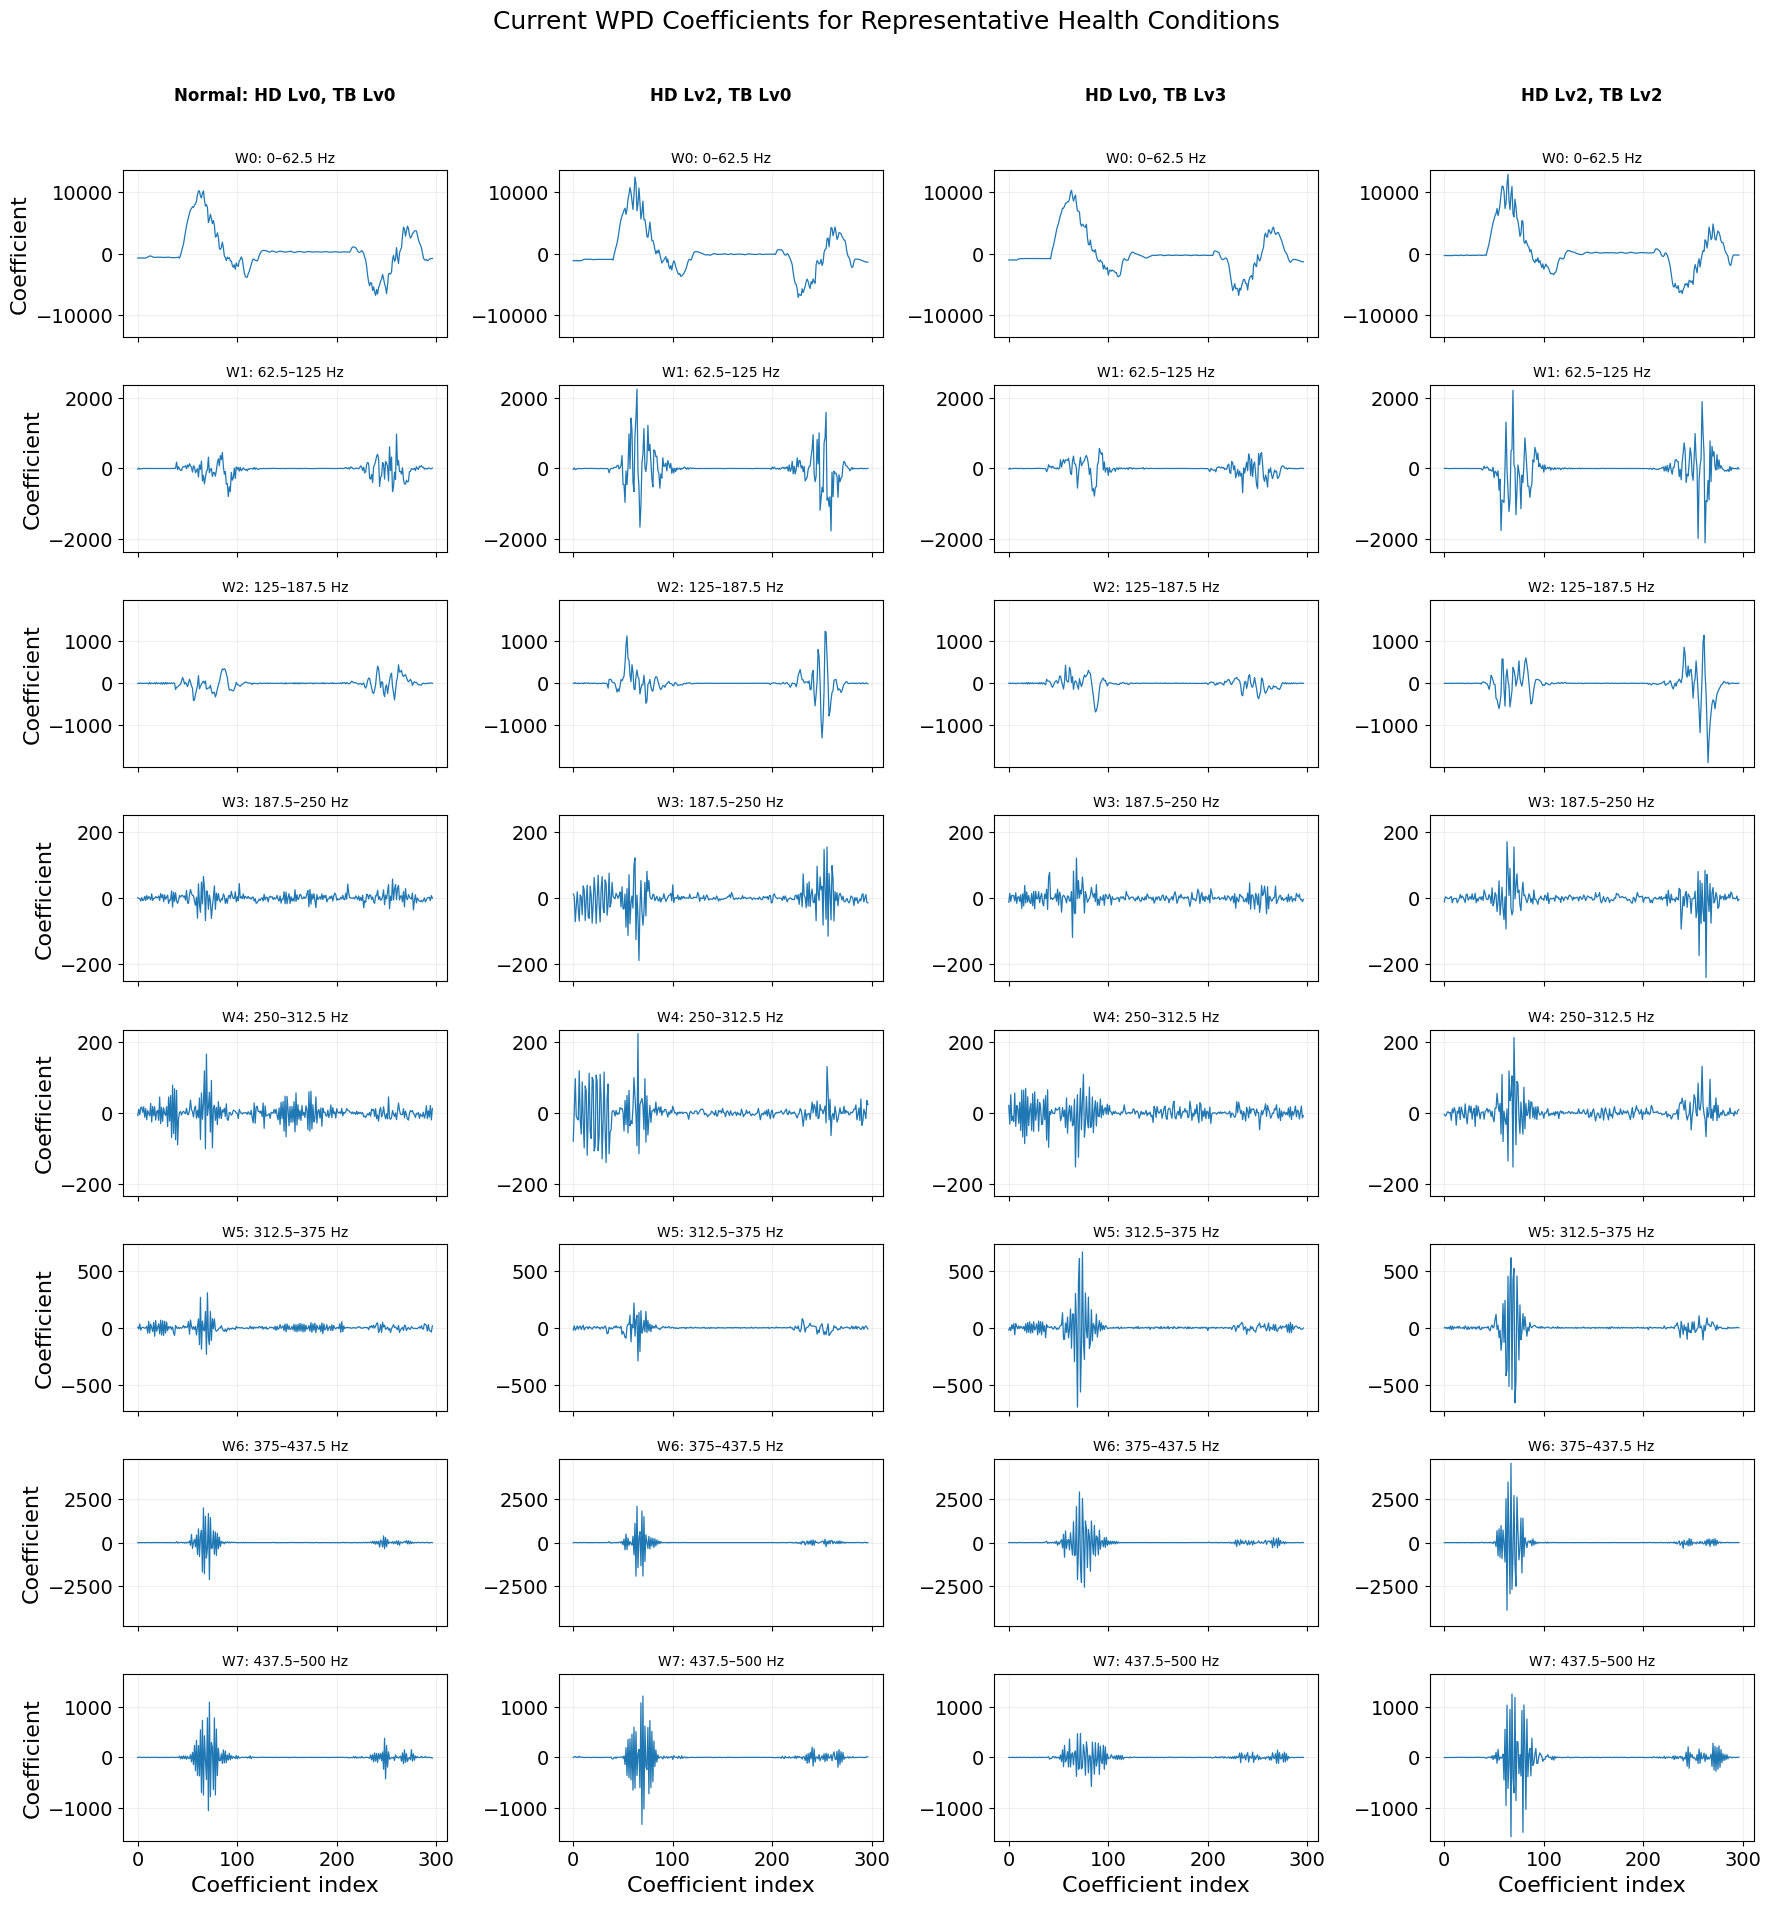

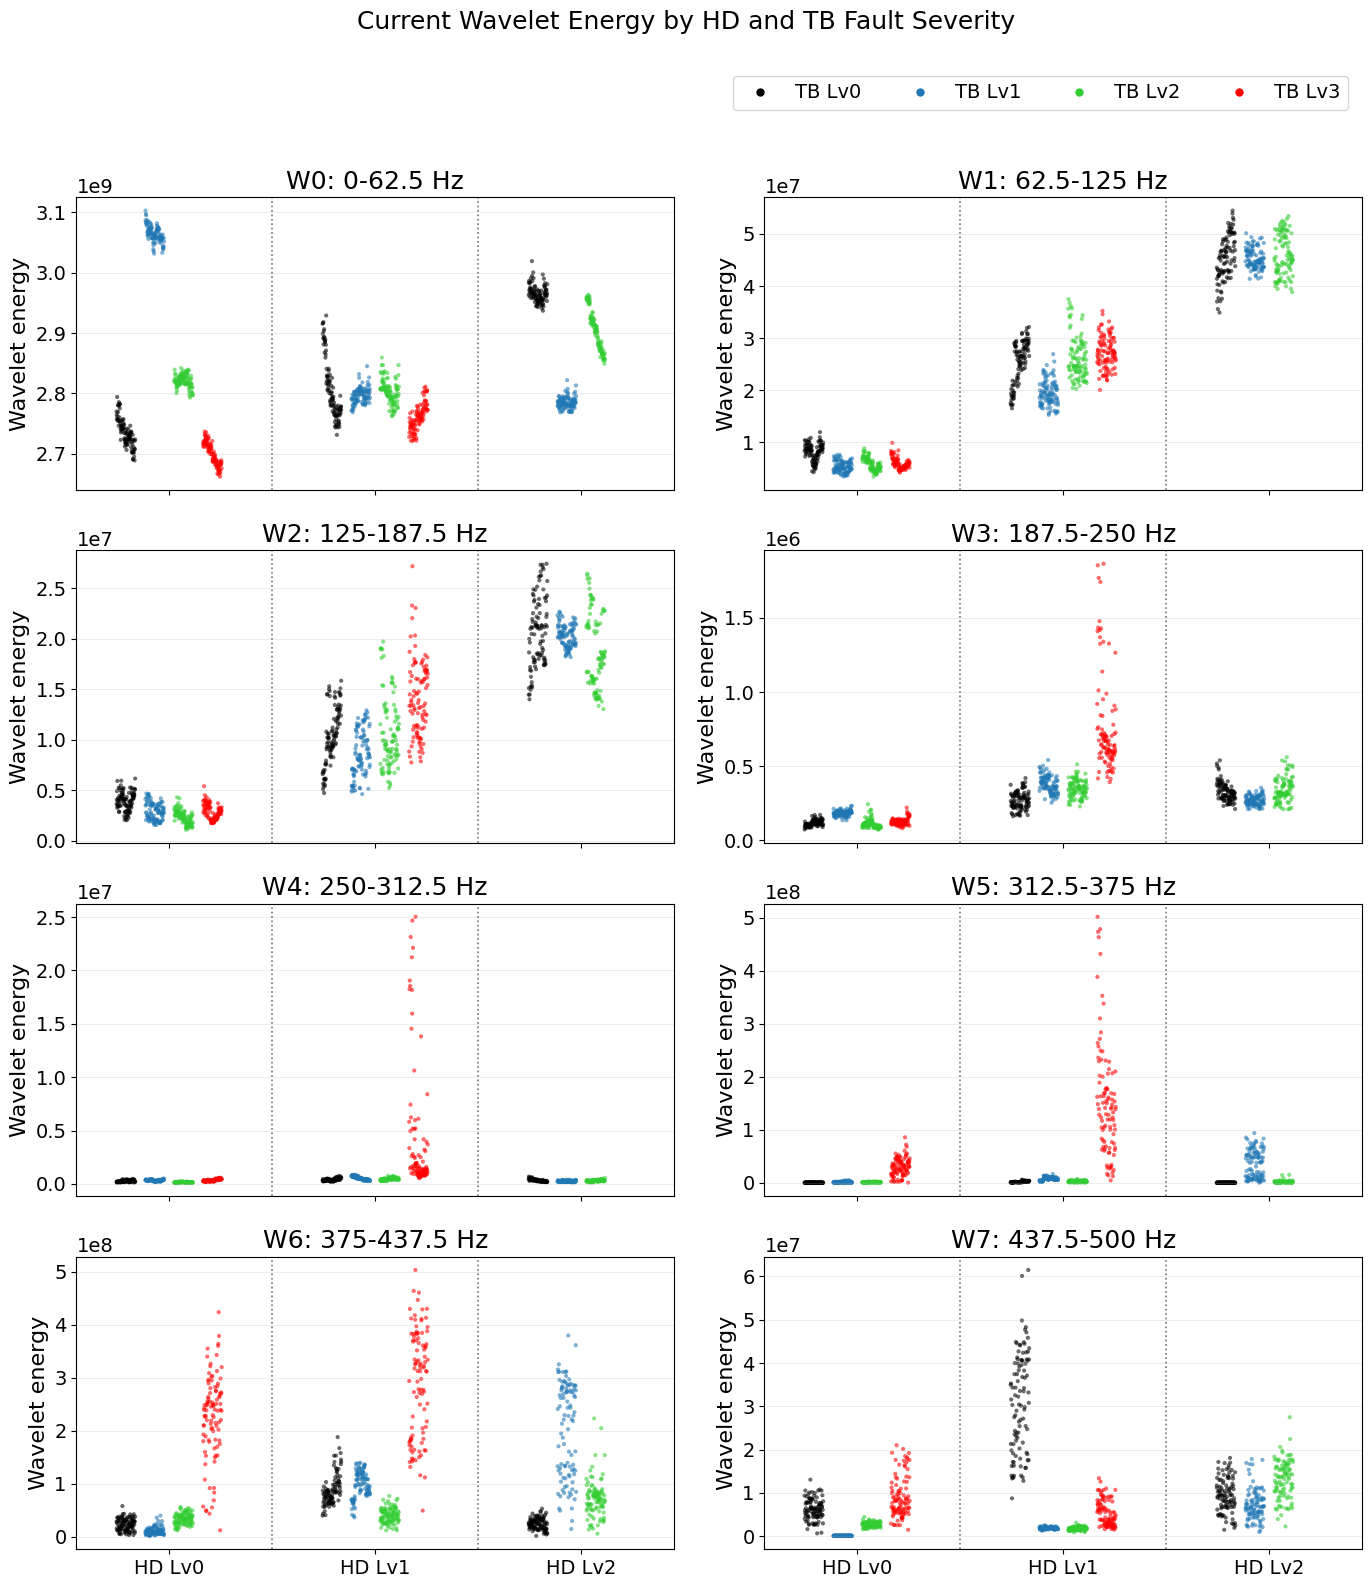

In [ ]:
# Compute current WPD coefficients for representative signals in frequency order
frequency_bands = [(i * 62.5, (i + 1) * 62.5) for i in range(8)]
case_wpd = {}
for file_name, _ in COMPARISON_CASES:
    wp = pywt.WaveletPacket(
        case_data[file_name][0][:, 0], wavelet="db6", mode="symmetric", maxlevel=3
    )
    case_wpd[file_name] = [
        np.asarray(node.data, dtype=float) for node in wp.get_level(3, order="freq")
    ]

# Plot WPD coefficients with a common amplitude scale across conditions in each band
fig, axes = plt.subplots(8, 4, figsize=(18, 19), sharex="col")
for band, (low, high) in enumerate(frequency_bands):
    limit = max(
        1,
        1.05
        * max(np.max(np.abs(case_wpd[name][band])) for name, _ in COMPARISON_CASES),
    )
    for case, (file_name, condition) in enumerate(COMPARISON_CASES):
        ax = axes[band, case]
        ax.plot(case_wpd[file_name][band], color="tab:blue", lw=0.9)
        ax.set_ylim(-limit, limit)
        ax.set_title(f"W{band}: {low:g}–{high:g} Hz", fontsize=10); ax.grid(alpha=0.2)
        if case == 0:
            ax.set_ylabel("Coefficient")
        if band == 0:
            ax.text(
                0.5,
                1.42,
                condition,
                transform=ax.transAxes,
                ha="center",
                fontsize=12,
                fontweight="bold",
            )
        if band == 7:
            ax.set_xlabel("Coefficient index")
fig.suptitle("Current WPD Coefficients for Representative Health Conditions", y=1.005)
fig.tight_layout()
plt.show()

# Compare current wavelet energy by HD and TB severity
# Select current wavelet energy columns and reorder them by frequency
natural_paths = ["aaa", "aad", "ada", "add", "daa", "dad", "dda", "ddd"]
frequency_paths = ["aaa", "aad", "add", "ada", "dda", "ddd", "dad", "daa"]
freq_from_nat = [natural_paths.index(path) for path in frequency_paths]
nat_we_cols = np.arange(13, 112, 14)
freq_we_cols = nat_we_cols[freq_from_nat]
current_we = feat_robot[:, freq_we_cols]

# Read HD and TB severity labels and assign colors to TB levels
hd_level = labseg[:, 2].astype(int)
tb_level = labseg[:, 0].astype(int)
tb_colors = {0: "black", 1: "tab:blue", 2: "limegreen", 3: "red"}

# Plot wavelet energy by HD level with horizontal offsets for TB levels
fig, axes = plt.subplots(4, 2, figsize=(14, 16), sharex=True)
for band_index, ax in enumerate(axes.flat):
    for hd in range(3):
        for tb in range(4):
            sel = np.flatnonzero((hd_level == hd) & (tb_level == tb))
            if sel.size == 0:
                continue
            center = hd + (tb - 1.5) * 0.14
            spread = np.linspace(-0.045, 0.045, sel.size)
            ax.scatter(
                center + spread,
                current_we[sel, band_index],
                s=9,
                color=tb_colors[tb],
                alpha=0.58,
                edgecolors="none",
            )
    ax.axvline(0.5, color="0.45", ls=":", lw=1.2)
    ax.axvline(1.5, color="0.45", ls=":", lw=1.2)
    low, high = frequency_bands[band_index]
    ax.set_title(f"W{band_index}: {low:g}-{high:g} Hz"); ax.set_ylabel("Wavelet energy")
    ax.grid(axis="y", alpha=0.22)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_xlim(-0.45, 2.45); ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["HD Lv0", "HD Lv1", "HD Lv2"])
print("\n")

# Add a shared legend for TB severity and finalize the figure layout
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markersize=6,
        markerfacecolor=tb_colors[lv],
        markeredgecolor="none",
        label=f"TB Lv{lv}",
    )
    for lv in range(4)
]
fig.legend(
    handles=legend_handles,
    loc="upper right",
    ncol=4,
    frameon=True,
    bbox_to_anchor=(0.98, 0.96),
)
fig.suptitle("Current Wavelet Energy by HD and TB Fault Severity", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 3. Feature selection by Spearman & FDR

Features are ranked separately for HD and TB by combining Spearman correlation and Fisher Discriminant Ratio (FDR). The composite score is `alpha * Spearman + (1-alpha) * FDR` with `alpha = 0.8`.

### Functions for scoring

In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.signal import find_peaks
from scipy.stats import spearmanr
from scipy.spatial.distance import pdist, squareform
from sklearn.manifold import TSNE

# Purpose: fisher discriminant ratio: between-class to within-class variance ratio.
# Input: means, standard_deviations.
# Output: returned num / den if den > 0 else 0.0.
# Used in: robot fault diagnosis.
def calculate_fdr(means, standard_deviations):
    means = np.asarray(means, dtype=float)
    standard_deviations = np.asarray(standard_deviations, dtype=float)
    mean_avg = np.mean(means)
    num = np.sum((mean_avg - means) ** 2)
    den = np.sum(standard_deviations**2)
    return num / den if den > 0 else 0.0

# Purpose: min-max normalisation to [0, 1]. returns zeros if span is zero.
# Input: values.
# Output: returned np.zeros_like(values) if span == 0 else (values - np.nanmin(values)) / span.
# Used in: robot fault diagnosis.
def minmax(values):
    values = np.asarray(values, dtype=float)
    span = np.nanmax(values) - np.nanmin(values)
    return np.zeros_like(values) if span == 0 else (values - np.nanmin(values)) / span

# Purpose: rank features by Spearman + FDR score for one health component.
# Input: features, labels, target_column, fixed_column, alpha.
# Output: computed result for the specified inputs.
# Used in: robot fault diagnosis.
def rank_features(features, labels, target_column, fixed_column, alpha=0.8):
    features = np.asarray(features, dtype=float)
    labels = np.asarray(labels)
    feat_mean = np.nanmean(features, axis=0)
    feat_std = np.nanstd(features, axis=0, ddof=1)
    normalized = np.divide(
        features - feat_mean, feat_std, out=np.zeros_like(features), where=feat_std > 0
    )
    spearman_total = np.zeros(features.shape[1])
    fdr_total = np.zeros(features.shape[1])
    for fixed_level in np.unique(labels[:, fixed_column]):
        idx = labels[:, fixed_column] == fixed_level
        target = labels[idx, target_column]
        if np.unique(target).size < 2:
            continue
        for j in range(features.shape[1]):
            vals = normalized[idx, j]
            corr = spearmanr(target, vals).statistic
            if np.isfinite(corr):
                spearman_total[j] += corr
            means = [np.mean(vals[target == lv]) for lv in np.unique(target)]
            stds = [np.std(vals[target == lv], ddof=1) for lv in np.unique(target)]
            fdr_total[j] += calculate_fdr(means, stds)
    score = alpha * minmax(np.abs(spearman_total)) + (1 - alpha) * minmax(
        np.abs(fdr_total)
    )
    order = np.argsort(score)[::-1]
    return {
        "normalized_features": normalized,
        "spearman": spearman_total,
        "fdr": fdr_total,
        "score": score,
        "order": order,
    }

feature_name_list = [str(v) for v in np.asarray(feat_name).reshape(-1)]

### Feature ranking for HD & TB

In [ ]:
hd_result = rank_features(feat_robot, labseg, target_column=2, fixed_column=0, alpha=0.8)
tb_result = rank_features(feat_robot, labseg, target_column=0, fixed_column=2, alpha=0.8)

# Purpose: make rank table.
# Input: result.
# Output: computed result for the specified inputs.
# Used in: robot fault diagnosis.
def make_rank_table(result):
    return pd.DataFrame(
        {
            "Rank": np.arange(1, len(result["order"]) + 1),
            "Feature": [feature_name_list[i] for i in result["order"]],
            "Score": result["score"][result["order"]],
            "Spearman": result["spearman"][result["order"]],
            "FDR": result["fdr"][result["order"]],
        }
    )

print("HD feature ranking (top 10):")
display(make_rank_table(hd_result).head(10))
print("TB feature ranking (top 10):")
display(make_rank_table(tb_result).head(10))

HD feature ranking (top 10):


,Rank,Feature,Score,Spearman,FDR
0,1,Cur-W1-STD,1.000000,3.694479,152.822517
1,2,Cur-W1-RMS,0.998816,3.694479,151.917716
2,3,Cur-WE1,0.984849,3.694479,141.245551
3,4,Cur-W1-SE,0.981317,-3.694479,138.547166
4,5,Cur-W1-P2P,0.871680,3.684061,56.501581
5,6,Cur-W0-KUR,0.861820,3.117703,142.956123
6,7,Cur-W3-STD,0.846987,3.661622,41.357595
7,8,Cur-W3-RMS,0.845972,3.660019,40.848012
8,9,Cur-WE3,0.842918,3.660019,38.514443
9,10,Cur-W3-SE,0.842428,-3.661999,37.811303


TB feature ranking (top 10):


,Rank,Feature,Score,Spearman,FDR
0,1,Vel-W0-SF,0.859504,-2.496198,25.977197
1,2,Cur-W7-MF,0.683255,2.073531,8.191978
2,3,Cur-W7-Peak(Max),0.669244,2.016884,10.002724
3,4,Cur-W7-P2P,0.663553,1.996302,10.398726
4,5,Cur-W7-SF,0.649177,1.949484,10.675059
5,6,Cur-W7-RMS,0.644852,1.935336,10.767247
6,7,Cur-W7-STD,0.644815,1.935278,10.759241
7,8,Cur-W7-SE,0.632530,-1.940497,4.666975
8,9,Cur-WE7,0.631740,1.935336,5.044238
9,10,Cur-W7-IF,0.606555,1.854351,5.383624


### Selected features

The paper selects the threshold at the largest meaningful gap in the rounded-score distribution. Features above the threshold are kept; highly correlated pairs are pruned.

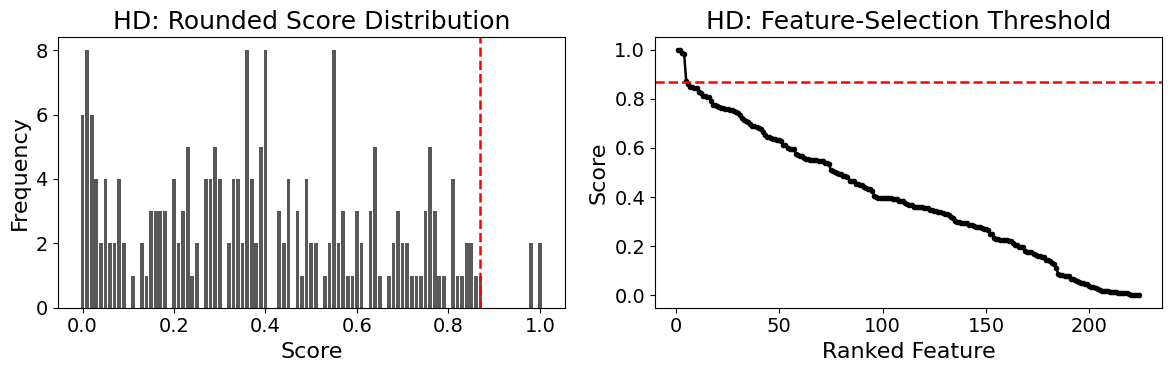

HD threshold: 0.87  |  selected: 5 features


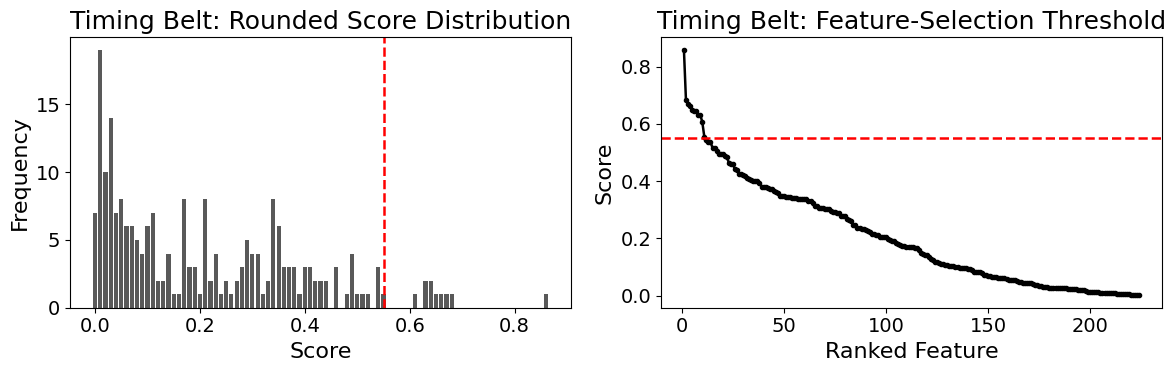

Timing Belt threshold: 0.55  |  selected: 11 features


In [ ]:
# Purpose: find the score threshold via gap analysis; return (threshold, selected_indices).
# Input: score, order, component_name.
# Output: returned (threshold, selected).
# Used in: robot fault diagnosis.
def score_threshold(score, order, component_name):
    sorted_score = score[order]
    rounded_score = np.round(sorted_score, 2)
    values, counts = np.unique(rounded_score, return_counts=True)
    weighted_diff = np.diff(values) / counts[1:]
    peaks, _ = find_peaks(weighted_diff)
    if peaks.size >= 4:
        prom_change = np.zeros(peaks.size)
        for idx in range(3, peaks.size):
            prev_mean = np.mean(weighted_diff[peaks[idx - 3 : idx]])
            if prev_mean > 0:
                prom_change[idx] = (
                    100 * (weighted_diff[peaks[idx]] - prev_mean) / prev_mean
                )
        selected_peak = peaks[np.argmax(prom_change)]
    else:
        selected_peak = int(np.argmax(weighted_diff))
    threshold = values[selected_peak]
    selected = order[score[order] >= threshold]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(values, counts, width=0.008, color="0.35")
    axes[0].axvline(threshold, color="red", linestyle="--")
    axes[0].set_xlabel("Score"); axes[0].set_ylabel("Frequency")
    axes[0].set_title(f"{component_name}: Rounded Score Distribution")
    axes[1].plot(np.arange(1, len(sorted_score) + 1), sorted_score, "k.-")
    axes[1].axhline(threshold, color="red", linestyle="--")
    axes[1].set_xlabel("Ranked Feature"); axes[1].set_ylabel("Score")
    axes[1].set_title(f"{component_name}: Feature-Selection Threshold")
    plt.tight_layout(); plt.show()
    print(
        f"{component_name} threshold: {format_number(threshold, '.2f')}  |  selected:"
        f" {len(selected)} features"
    )
    return threshold, selected

hd_threshold, hd_selected = score_threshold(hd_result["score"], hd_result["order"], "HD")
tb_threshold, tb_selected = score_threshold(
    tb_result["score"], tb_result["order"], "Timing Belt"
)

### Remove redundant features and summarize the selection

In [ ]:
CORRELATION_LIMIT = 0.95

# Purpose: drop features that are highly correlated with an already-selected one.
# Input: features, candidates, correlation_limit.
# Output: returned (np.asarray(selected, dtype=int), pd.DataFrame(rejected)).
# Used in: robot fault diagnosis.
def remove_redundant_features(features, candidates, correlation_limit=0.95):
    features = np.asarray(features, dtype=float)
    candidates = np.asarray(candidates, dtype=int)
    corr_mat = pd.DataFrame(features).corr(method="spearman").abs().to_numpy()
    selected, rejected = [], []
    for candidate in candidates:
        if not selected:
            selected.append(candidate)
            continue
        sel_corrs = corr_mat[candidate, selected]
        max_pos = int(np.nanargmax(sel_corrs))
        max_corr = sel_corrs[max_pos]
        if max_corr < correlation_limit:
            selected.append(candidate)
        else:
            rejected.append(
                {
                    "Rejected feature": feature_name_list[candidate],
                    "Retained feature": feature_name_list[selected[max_pos]],
                    "|Spearman correlation|": max_corr,
                }
            )
    return np.asarray(selected, dtype=int), pd.DataFrame(rejected)

hd_selected_nonredundant, hd_rejected = remove_redundant_features(
    feat_robot, hd_selected, CORRELATION_LIMIT
)
tb_selected_nonredundant, tb_rejected = remove_redundant_features(
    feat_robot, tb_selected, CORRELATION_LIMIT
)

# Purpose: selected feature table.
# Input: result, selected.
# Output: computed result for the specified inputs.
# Used in: robot fault diagnosis.
def selected_feature_table(result, selected):
    rank_lookup = {
        feat_idx: rank for rank, feat_idx in enumerate(result["order"], start=1)
    }
    return pd.DataFrame(
        {
            "Rank": [rank_lookup[i] for i in selected],
            "Feature": [feature_name_list[i] for i in selected],
            "Score": result["score"][selected],
        }
    )

hd_final_table = selected_feature_table(hd_result, hd_selected_nonredundant)
tb_final_table = selected_feature_table(tb_result, tb_selected_nonredundant)

print(
    f"HD: {len(hd_selected)} -> {len(hd_selected_nonredundant)} after redundancy"
    " removal"
)
display(hd_final_table)
print(
    f"TB: {len(tb_selected)} -> {len(tb_selected_nonredundant)} after redundancy"
    " removal"
)
display(tb_final_table)
print("Rejected HD features")
display(hd_rejected)
print("Rejected TB features")
display(tb_rejected)

HD: 5 -> 1 after redundancy removal


,Rank,Feature,Score
0,1,Cur-W1-STD,1.0


TB: 11 -> 4 after redundancy removal


,Rank,Feature,Score
0,1,Vel-W0-SF,0.859504
1,2,Cur-W7-MF,0.683255
2,3,Cur-W7-Peak(Max),0.669244
3,11,Vel-W7-SF,0.554561


Rejected HD features


,Rejected feature,Retained feature,|Spearman correlation|
0,Cur-W1-RMS,Cur-W1-STD,0.999946
1,Cur-WE1,Cur-W1-STD,0.999946
2,Cur-W1-SE,Cur-W1-STD,0.999809
3,Cur-W1-P2P,Cur-W1-STD,0.961663


Rejected TB features


,Rejected feature,Retained feature,|Spearman correlation|
0,Cur-W7-P2P,Cur-W7-Peak(Max),0.996182
1,Cur-W7-SF,Cur-W7-MF,0.975237
2,Cur-W7-RMS,Cur-W7-Peak(Max),0.983039
3,Cur-W7-STD,Cur-W7-Peak(Max),0.983025
4,Cur-W7-SE,Cur-W7-Peak(Max),0.984999
5,Cur-WE7,Cur-W7-Peak(Max),0.983039
6,Cur-W7-IF,Cur-W7-MF,0.952683


### Visual comparison of the selected features

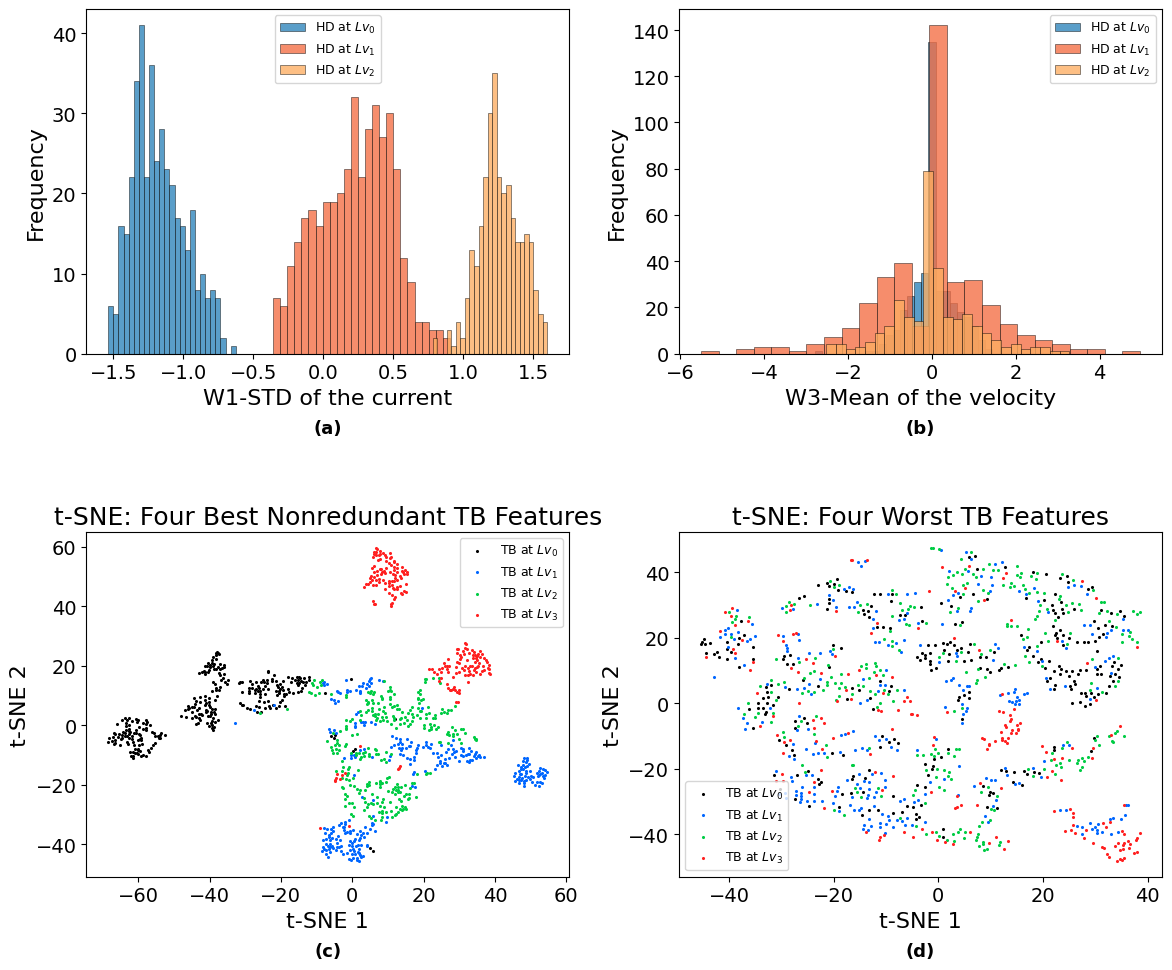

HD best feature: Cur-W1-STD
HD worst feature: Vel-W3-Mean
TB best four: ['Vel-W0-SF', 'Cur-W7-MF', 'Cur-W7-Peak(Max)', 'Vel-W7-SF']


In [ ]:
# Purpose: convert 'cur-w1-std' -> 'std of the current' for axis labels.
# Input: name.
# Output: returned f'{feature} of the {signal_name}'.
# Used in: robot fault diagnosis.
def feature_axis_label(name):
    parts = name.split("-", 1)
    channel = parts[0]
    feature = parts[1] if len(parts) == 2 else name
    signal_name = "current" if channel == "Cur" else "velocity"
    return f"{feature} of the {signal_name}"

# Purpose: t-sne embedding with Mahalanobis pre-distance matrix.
# Input: features, random_state.
# Output: computed result for the specified inputs.
# Used in: robot fault diagnosis.
def mahalanobis_tsne(features, random_state=0):
    features = np.asarray(features, dtype=float)
    inv_cov = np.linalg.pinv(np.cov(features, rowvar=False))
    dist_mat = squareform(pdist(features, metric="mahalanobis", VI=inv_cov))
    return TSNE(
        n_components=2,
        perplexity=30,
        metric="precomputed",
        method="exact",
        init="random",
        learning_rate="auto",
        random_state=random_state,
    ).fit_transform(dist_mat)

normalized_features = hd_result["normalized_features"]
hd_best = int(hd_selected_nonredundant[0])
hd_worst = int(hd_result["order"][-1])
tb_best_four = np.asarray(tb_selected_nonredundant[:4], dtype=int)
tb_worst_four = np.asarray(tb_result["order"][-4:], dtype=int)

if tb_best_four.size < 4:
    raise ValueError("At least four nonredundant TB features are required.")

tb_emb_best = mahalanobis_tsne(normalized_features[:, tb_best_four], random_state=0)
tb_emb_worst = mahalanobis_tsne(normalized_features[:, tb_worst_four], random_state=0)

hd_colors = ["#2b83ba", "#f46d43", "#fdae61"]
tb_colors = ["black", "#0066ff", "#00cc44", "#ff2020"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# HD feature histograms: best vs worst
for level, color in zip([0, 1, 2], hd_colors):
    idx = labseg[:, 2] == level
    for ax, feat_idx in zip(axes[0, :], [hd_best, hd_worst]):
        ax.hist(
            normalized_features[idx, feat_idx],
            bins=25,
            color=color,
            edgecolor="black",
            linewidth=0.4,
            alpha=0.78,
            label=rf"HD at $Lv_{{{level}}}$",
        )
axes[0, 0].set_xlabel(feature_axis_label(feature_name_list[hd_best]))
axes[0, 1].set_xlabel(feature_axis_label(feature_name_list[hd_worst]))
for ax in axes[0, :]:
    ax.set_ylabel("Frequency"); ax.legend(fontsize=9, frameon=True)

# TB t-sne: best four vs worst four
for level, color in zip([0, 1, 2, 3], tb_colors):
    idx = labseg[:, 0] == level
    for ax, emb in zip(axes[1, :], [tb_emb_best, tb_emb_worst]):
        ax.scatter(
            emb[idx, 0],
            emb[idx, 1],
            s=6,
            c=color,
            marker=".",
            label=rf"TB at $Lv_{{{level}}}$",
        )

axes[1, 0].set_title("t-SNE: Four Best Nonredundant TB Features")
axes[1, 1].set_title("t-SNE: Four Worst TB Features")
for ax in axes[1, :]:
    ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
    ax.legend(fontsize=9, frameon=True)

for ax, panel in zip(axes.ravel(), ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(
        0.5,
        -0.19,
        panel,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=13,
        fontweight="bold",
    )

plt.tight_layout(h_pad=3.0); plt.show()
print("HD best feature:", feature_name_list[hd_best])
print("HD worst feature:", feature_name_list[hd_worst])
print("TB best four:", [feature_name_list[i] for i in tb_best_four])

## 4. ANN training & application

Estimates HIs of HD and TB. HD Lv0-Lv2 are mapped to HI values {0, 0.5, 1}; TB Lv0-Lv3 to {0, 1/3, 2/3, 1}.

### Prepare ANN inputs and HI targets

In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# Input features: one HD feature + four TB features
ann_feature_indices = np.r_[
    np.asarray(hd_selected_nonredundant[:1], dtype=int),
    np.asarray(tb_selected_nonredundant[:4], dtype=int),
]
if ann_feature_indices.size != 5:
    raise ValueError("Exactly one HD and four TB features are required.")
if np.unique(ann_feature_indices).size != ann_feature_indices.size:
    raise ValueError("HD and TB selections contain a duplicate feature.")

ann_feature_names = [feature_name_list[i] for i in ann_feature_indices]
x_ann_raw = np.asarray(feat_robot[:, ann_feature_indices], dtype=np.float64)
hd_level = np.asarray(labseg[:, 2], dtype=int)
tb_level = np.asarray(labseg[:, 0], dtype=int)
hi_targets = np.column_stack([hd_level / 2.0, tb_level / 3.0]).astype(np.float64)

print(f"ANN inputs: {x_ann_raw.shape}  |  HI targets: {hi_targets.shape}")
print("Selected features:", ann_feature_names)

ANN inputs: (1100, 5)  |  HI targets: (1100, 2)
Selected features: ['Cur-W1-STD', 'Vel-W0-SF', 'Cur-W7-MF', 'Cur-W7-Peak(Max)', 'Vel-W7-SF']


### Dataset split

In [ ]:
# User settings: change these values to repeat the experiment
random_state = 42  # Random seed for reproducible splitting
test_ratio = 0.30  # Fraction reserved for independent testing
validation_ratio = 0.20  # Validation fraction of development data

sample_index = np.arange(len(x_ann_raw))
condition_code = tb_level * 10 + hd_level

development_index, test_index = train_test_split(
    sample_index,
    test_size=test_ratio,
    stratify=condition_code,
    random_state=random_state,
)

ann_train_pos, validation_pos = train_test_split(
    np.arange(len(development_index)),
    test_size=validation_ratio,
    stratify=condition_code[development_index],
    random_state=random_state,
)

ann_train_index = development_index[ann_train_pos]
validation_index = development_index[validation_pos]

scaler_ann = StandardScaler()
x_ann_train = scaler_ann.fit_transform(x_ann_raw[ann_train_index])
x_validation = scaler_ann.transform(x_ann_raw[validation_index])
x_ann_test = scaler_ann.transform(x_ann_raw[test_index])
y_ann_train = hi_targets[ann_train_index]
y_validation = hi_targets[validation_index]
y_test = hi_targets[test_index]

display(
    pd.DataFrame(
        {
            "Subset": ["ANN training", "Validation", "Independent test"],
            "Samples": [len(ann_train_index), len(validation_index), len(test_index)],
            "Percent of total": [
                100 * len(ann_train_index) / len(sample_index),
                100 * len(validation_index) / len(sample_index),
                100 * len(test_index) / len(sample_index),
            ],
        }
    ).style.format({"Percent of total": "{:.1f}%"})
)

,Subset,Samples,Percent of total
0,ANN training,616,56.0%
1,Validation,154,14.0%
2,Independent test,330,30.0%


### Train and validate ANN

The architecture is `5 inputs → 20 tanh neurons → 2 linear outputs`. Trained with Adam and early stopping on validation MSE.

ANN training time: 100.59 s
ANN structure: 5-20-2  |  Best epoch: 725
Train RMSE   — HD: 0.0294, TB: 0.0652
Val RMSE     — HD: 0.0385, TB: 0.0889


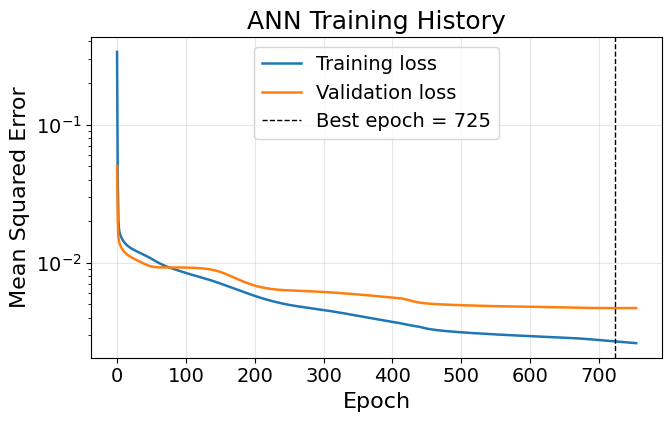

In [ ]:
# User settings: grouped controls for this experiment
hidden_neurons = 20
learning_rate = 0.005
maximum_epochs = 800
batch_size = 32
patience = 30

# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting

import time

# Set the epoch reporting interval

tf.keras.utils.set_random_seed(random_state)

ann_model = models.Sequential(
    [
        layers.Input(shape=(x_ann_train.shape[1],)),
        layers.Dense(hidden_neurons, activation="tanh"),
        layers.Dense(2, activation="linear"),
    ]
)
ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss="mean_squared_error",
)

start_time = time.time()
# Report the model and data before training
show_model_info(ann_model, x_ann_train, x_validation, x_ann_test)
training_started = time.perf_counter()
history = ann_model.fit(
    x_ann_train,
    y_ann_train,
    validation_data=(x_validation, y_validation),
    epochs=maximum_epochs,
    batch_size=batch_size,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    ]
    + [training_progress(progress_interval)],
    verbose=0,
)
report_training(history, training_started)
print(f"ANN training time: {format_number(time.time() - start_time, '.2f')} s")

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
train_prediction = ann_model.predict(x_ann_train, verbose=0)
val_prediction = ann_model.predict(x_validation, verbose=0)
train_rmse = np.sqrt(np.mean((y_ann_train - train_prediction) ** 2, axis=0))
val_rmse = np.sqrt(np.mean((y_validation - val_prediction) ** 2, axis=0))

print(f"ANN structure: 5-{hidden_neurons}-2  |  Best epoch: {best_epoch}")
print(
    f"Train RMSE   — HD: {format_number(train_rmse[0], '.4f')}, TB:"
    f" {format_number(train_rmse[1], '.4f')}"
)
print(
    f"Val RMSE     — HD: {format_number(val_rmse[0], '.4f')}, TB:"
    f" {format_number(val_rmse[1], '.4f')}"
)

plt.figure(figsize=(7, 4.5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.axvline(
    best_epoch - 1,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"Best epoch = {best_epoch}",
)
plt.xlabel("Epoch"); plt.ylabel("Mean Squared Error"); plt.title("ANN Training History")
plt.yscale("log")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

### Apply ANN to test set

Independent test samples: 330
HD test RMSE: 0.0432
TB test RMSE: 0.1036


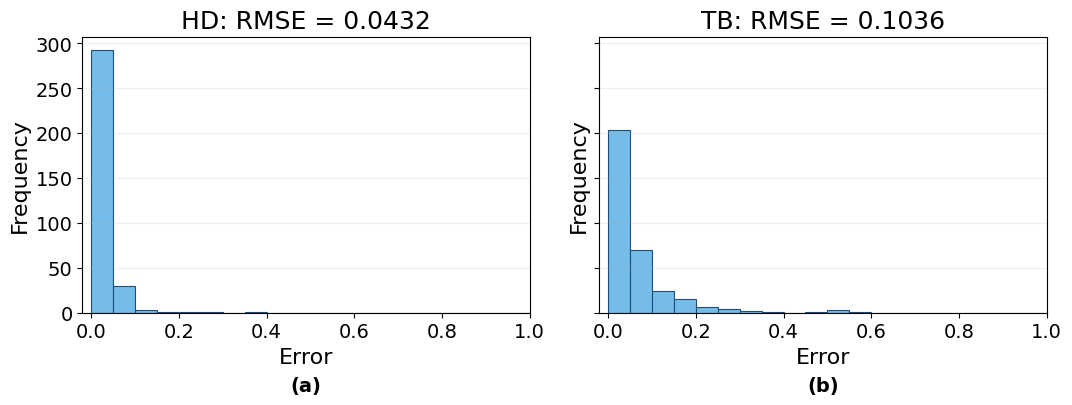

In [ ]:
# Report the independent test input before prediction
print("Test samples:", len(x_ann_test))

test_prediction = ann_model.predict(x_ann_test, verbose=0)
test_rmse = np.sqrt(np.mean((y_test - test_prediction) ** 2, axis=0))
abs_error = np.abs(y_test - test_prediction)

print(f"Independent test samples: {len(test_index)}")
print(f"HD test RMSE: {format_number(test_rmse[0], '.4f')}")
print(f"TB test RMSE: {format_number(test_rmse[1], '.4f')}")

bins = np.arange(0.0, 1.05, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for idx, (component, panel) in enumerate([("HD", "(a)"), ("TB", "(b)")]):
    axes[idx].hist(
        abs_error[:, idx],
        bins=bins,
        color="#75bce8",
        edgecolor="#1f4e79",
        linewidth=0.8,
    )
    axes[idx].set_xlim(-0.02, 1.0); axes[idx].set_xlabel("Error")
    axes[idx].set_ylabel("Frequency")
    axes[idx].set_title(f"{component}: RMSE = {format_number(test_rmse[idx], '.4f')}")
    axes[idx].text(
        0.5,
        -0.23,
        panel,
        transform=axes[idx].transAxes,
        ha="center",
        va="top",
        fontsize=14,
        fontweight="bold",
    )
    axes[idx].grid(True, axis="y", alpha=0.2)
plt.tight_layout(); plt.show()

### Confusion matrices for severity levels

HD severity accuracy: 0.9939  |  TB severity accuracy: 0.9364


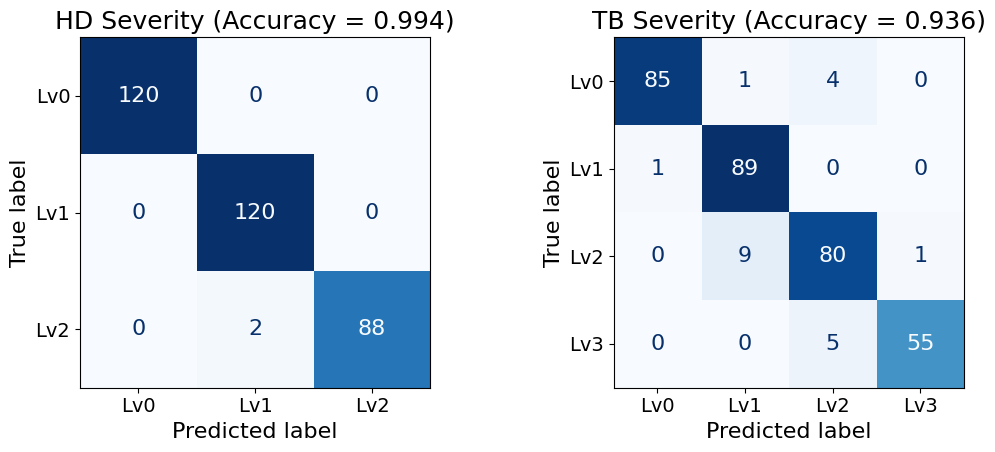

In [ ]:
# Purpose: map continuous HI predictions to the nearest discrete severity level.
# Input: predicted_hi, allowed_hi.
# Output: computed result for the specified inputs.
# Used in: robot fault diagnosis.
def nearest_level(predicted_hi, allowed_hi):
    return np.argmin(
        np.abs(np.asarray(predicted_hi)[:, None] - np.asarray(allowed_hi)[None, :]),
        axis=1,
    )

hd_true_level = hd_level[test_index]
tb_true_level = tb_level[test_index]
hd_pred_level = nearest_level(test_prediction[:, 0], [0.0, 0.5, 1.0])
tb_pred_level = nearest_level(test_prediction[:, 1], [0.0, 1 / 3, 2 / 3, 1.0])

hd_accuracy = accuracy_score(hd_true_level, hd_pred_level)
tb_accuracy = accuracy_score(tb_true_level, tb_pred_level)
print(
    f"HD severity accuracy: {format_number(hd_accuracy, '.4f')}  |  TB severity"
    f" accuracy: {format_number(tb_accuracy, '.4f')}"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ConfusionMatrixDisplay(
    confusion_matrix(hd_true_level, hd_pred_level, labels=[0, 1, 2]),
    display_labels=["Lv0", "Lv1", "Lv2"],
).plot(cmap="Blues", values_format="d", ax=axes[0], colorbar=False)
axes[0].set_title(f"HD Severity (Accuracy = {format_number(hd_accuracy, '.3f')})")
ConfusionMatrixDisplay(
    confusion_matrix(tb_true_level, tb_pred_level, labels=[0, 1, 2, 3]),
    display_labels=["Lv0", "Lv1", "Lv2", "Lv3"],
).plot(cmap="Blues", values_format="d", ax=axes[1], colorbar=False)
axes[1].set_title(f"TB Severity (Accuracy = {format_number(tb_accuracy, '.3f')})")
plt.tight_layout(); plt.show()

## 5. Gaussian process regression

GPR represents S as a function of TB and HD HIs. Input: $(g_1^n, g_2^n)$ = (TB HI, HD HI); output: vibration RMS normalised to [0, 1].

### Prepare the GPR dataset

Use one RMS value from the complete vertical vibration signal of each raw file. Set TB HI = TB level / 3 and HD HI = HD level / 2 from the file labels. The 55 files provide 55 input-output pairs.

In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

# Assign TB and HD health indices from the raw-file labels
file_labels = np.vstack([parse_raw_file_name(path) for path in raw_files])
tb_hi = file_labels[:, 0].astype(float) / 3
hd_hi = file_labels[:, 2].astype(float) / 2
gpr_input = np.column_stack([tb_hi, hd_hi])

# Calculate one RMS value from the complete vibration signal of each file
vibration_rms = np.array([np.sqrt(np.mean(signal**2)) for signal in vibration_signals])
rms_min, rms_max = vibration_rms.min(), vibration_rms.max()
if rms_max <= rms_min:
    raise ValueError("Vibration RMS must vary across files for normalisation.")

print(f"GPR input: {gpr_input.shape}  |  Vibration RMS: {vibration_rms.shape}")
print(f"RMS range: {format_number(rms_min, '.4f')} to {format_number(rms_max, '.4f')}")

GPR input: (55, 2)  |  Vibration RMS: (55,)
RMS range: 0.1046 to 0.2104


### Construct the GPR model

A squared-exponential covariance function is used, plus a constant basis and white-noise kernel. Initial hyperparameters taken from the paper; optimised via maximum likelihood.

In [ ]:
initial_length_scale = 0.9525
initial_signal_std = 0.0467
initial_noise_std = 0.0130

# Subtract the mean RMS before GPR training and add it back to predictions
gpr_constant_mean = vibration_rms.mean()
vibration_residual = vibration_rms - gpr_constant_mean

gpr_kernel = ConstantKernel(
    constant_value=initial_signal_std**2, constant_value_bounds=(1e-4, 1.0)
) * RBF(
    length_scale=initial_length_scale, length_scale_bounds=(0.05, 10.0)
) + WhiteKernel(
    noise_level=initial_noise_std**2, noise_level_bounds=(1e-6, 0.1)
)

gpr_model = GaussianProcessRegressor(
    kernel=gpr_kernel, normalize_y=False, n_restarts_optimizer=10, random_state=42
)
gpr_model.fit(gpr_input, vibration_residual)

kernel = gpr_model.kernel_
noise_std = np.sqrt(kernel.k2.noise_level)
print(
    f"Optimized kernel: {kernel.k1} +"
    f" WhiteKernel(noise_level={format_number(noise_std, '.4f')}**2)"
)
print(
    "Log marginal likelihood:"
    f" {format_number(gpr_model.log_marginal_likelihood_value_, '.4f')}"
)

Optimized kernel: 0.0449**2 * RBF(length_scale=0.876) + WhiteKernel(noise_level=0.0097**2)
Log marginal likelihood: 164.0255


### GPR response surface and component responses

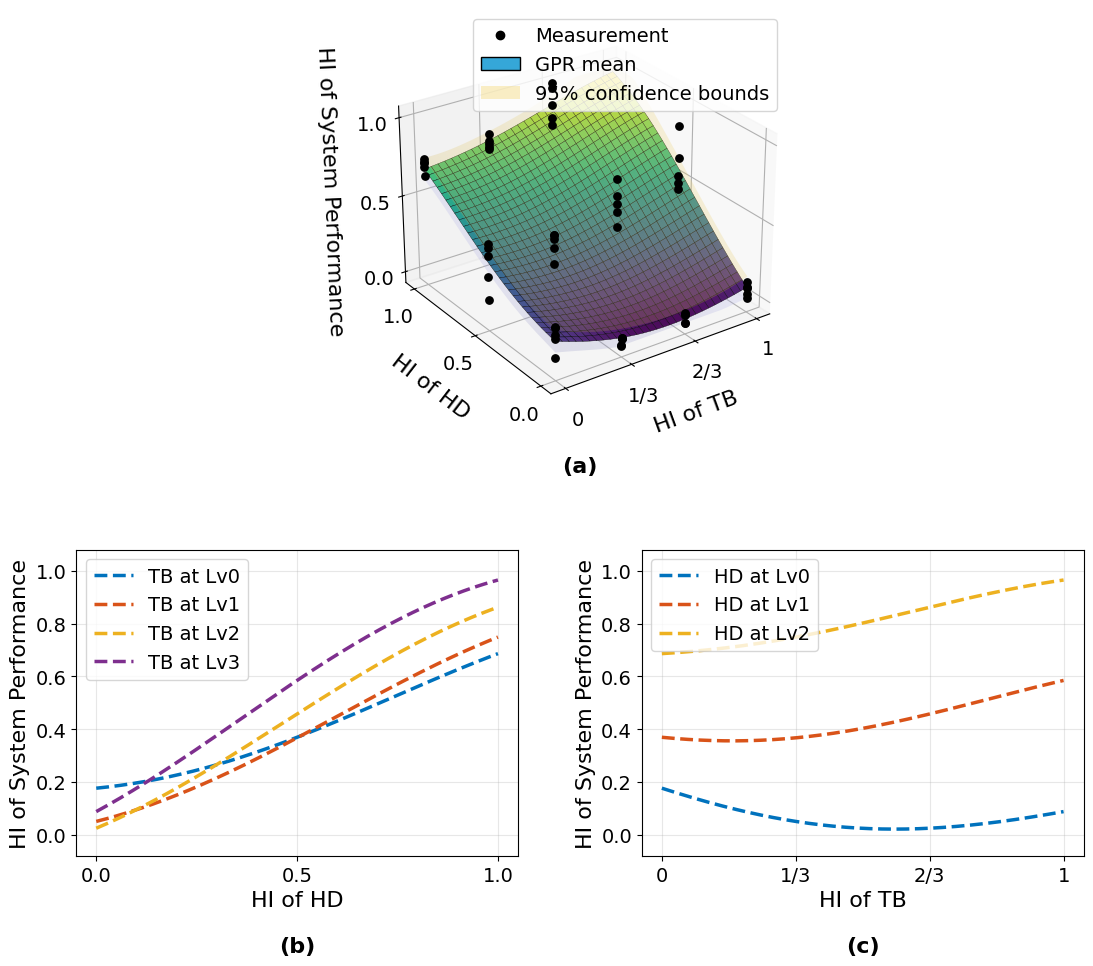

In [ ]:
# Create a 30-by-30 prediction grid over TB and HD health indices
grid_size = 30
tb_axis = np.linspace(0.0, 1.0, grid_size)
hd_axis = np.linspace(0.0, 1.0, grid_size)
tb_grid, hd_grid = np.meshgrid(tb_axis, hd_axis)
grid_input = np.column_stack([tb_grid.ravel(), hd_grid.ravel()])

# Predict vibration RMS and restore the mean subtracted before training
grid_rms_res, grid_pred_std = gpr_model.predict(grid_input, return_std=True)
grid_rms_mean = gpr_constant_mean + grid_rms_res

# Exclude measurement noise to obtain response uncertainty only
noise_var = gpr_model.kernel_.k2.noise_level
grid_latent_std = np.sqrt(np.maximum(grid_pred_std**2 - noise_var, 0.0))

# Convert RMS predictions to system HI and calculate 95% bounds clipped to [0, 1]
system_hi_mean = rms_to_system_hi(grid_rms_mean, rms_min, rms_max).reshape(tb_grid.shape)
system_hi_std = (grid_latent_std / (rms_max - rms_min)).reshape(tb_grid.shape)
system_hi_lower = np.clip(system_hi_mean - 1.96 * system_hi_std, 0.0, 1.0)
system_hi_upper = np.clip(system_hi_mean + 1.96 * system_hi_std, 0.0, 1.0)
measured_sys_hi = rms_to_system_hi(vibration_rms, rms_min, rms_max)

figure = plt.figure(figsize=(13, 11))
layout = figure.add_gridspec(2, 2, height_ratios=[1.35, 1.0], hspace=0.35, wspace=0.28)

# (A) 3-d response surface
ax_s = figure.add_subplot(layout[0, :], projection="3d")
ax_s.scatter(
    tb_hi, hd_hi, measured_sys_hi, color="black", s=28, depthshade=False, zorder=5
)
ax_s.plot_surface(
    tb_grid,
    hd_grid,
    system_hi_mean,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.25,
    alpha=0.95,
)
ax_s.plot_surface(
    tb_grid, hd_grid, system_hi_upper, color="#f4d35e", edgecolor="none", alpha=0.22
)
ax_s.plot_surface(
    tb_grid, hd_grid, system_hi_lower, color="#b8b8ff", edgecolor="none", alpha=0.22
)
ax_s.set_xlabel("HI of TB", labelpad=10); ax_s.set_ylabel("HI of HD", labelpad=10)
ax_s.set_zlabel("HI of System Performance", labelpad=10)
ax_s.set_xticks([0, 1 / 3, 2 / 3, 1]); ax_s.set_xticklabels(["0", "1/3", "2/3", "1"])
ax_s.set_yticks([0, 0.5, 1]); ax_s.set_zticks([0, 0.5, 1])
ax_s.view_init(elev=27, azim=-125)
ax_s.legend(
    handles=[
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor="black",
            markersize=6,
            label="Measurement",
        ),
        Patch(facecolor="#35a7d8", edgecolor="black", label="GPR mean"),
        Patch(facecolor="#f4d35e", alpha=0.35, label="95% confidence bounds"),
    ],
    loc="upper right",
)
ax_s.text2D(
    0.5,
    -0.08,
    "(a)",
    transform=ax_s.transAxes,
    ha="center",
    va="top",
    fontweight="bold",
)

# (B) HD slice response
ax_hd = figure.add_subplot(layout[1, 0])
hd_line = np.linspace(0.0, 1.0, 200)
for level, color, label in zip(
    [0.0, 1 / 3, 2 / 3, 1.0],
    ["#0072BD", "#D95319", "#EDB120", "#7E2F8E"],
    ["TB at Lv0", "TB at Lv1", "TB at Lv2", "TB at Lv3"],
):
    resp = gpr_constant_mean + gpr_model.predict(
        np.column_stack([np.full_like(hd_line, level), hd_line])
    )
    ax_hd.plot(
        hd_line,
        rms_to_system_hi(resp, rms_min, rms_max),
        "--",
        color=color,
        lw=2.5,
        label=label,
    )
ax_hd.set_xlabel("HI of HD"); ax_hd.set_ylabel("HI of System Performance")
ax_hd.set_xticks([0, 0.5, 1]); ax_hd.set_ylim(-0.08, 1.08); ax_hd.grid(True, alpha=0.3)
ax_hd.legend(loc="upper left")
ax_hd.text(
    0.5,
    -0.26,
    "(b)",
    transform=ax_hd.transAxes,
    ha="center",
    va="top",
    fontweight="bold",
)

# (C) TB slice response
ax_tb = figure.add_subplot(layout[1, 1])
tb_line = np.linspace(0.0, 1.0, 200)
for level, color, label in zip(
    [0.0, 0.5, 1.0],
    ["#0072BD", "#D95319", "#EDB120"],
    ["HD at Lv0", "HD at Lv1", "HD at Lv2"],
):
    resp = gpr_constant_mean + gpr_model.predict(
        np.column_stack([tb_line, np.full_like(tb_line, level)])
    )
    ax_tb.plot(
        tb_line,
        rms_to_system_hi(resp, rms_min, rms_max),
        "--",
        color=color,
        lw=2.5,
        label=label,
    )
ax_tb.set_xlabel("HI of TB"); ax_tb.set_ylabel("HI of System Performance")
ax_tb.set_xticks([0, 1 / 3, 2 / 3, 1]); ax_tb.set_xticklabels(["0", "1/3", "2/3", "1"])
ax_tb.set_ylim(-0.08, 1.08); ax_tb.grid(True, alpha=0.3); ax_tb.legend(loc="upper left")
ax_tb.text(
    0.5,
    -0.26,
    "(c)",
    transform=ax_tb.transAxes,
    ha="center",
    va="top",
    fontweight="bold",
)
plt.show()

## 6. What-if study and maintenance scenario

### Evaluate the current and restored states

For a consistent comparison, every scenario uses the same GPR model from Section 5.

In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter

# Purpose: GPR prediction with 95% ci for a single (TB, HD) point.
# Input: tb_value, hd_value.
# Output: returned (hi_mean, max(0.0, hi_mean - 1.96 * hi_std), min(1.0, hi_mean + 1.96
# * hi_std)).
# Used in: robot fault diagnosis.
def predict_system_hi(tb_value, hd_value):
    res_mean, res_std = gpr_model.predict(
        np.array([[tb_value, hd_value]]), return_std=True
    )
    res_std = np.sqrt(np.maximum(res_std**2 - gpr_model.kernel_.k2.noise_level, 0))
    hi_mean = float(rms_to_system_hi(gpr_constant_mean + res_mean[0], rms_min, rms_max))
    hi_std = float(res_std[0] / (rms_max - rms_min))
    return hi_mean, max(0.0, hi_mean - 1.96 * hi_std), min(1.0, hi_mean + 1.96 * hi_std)

current_hd_level, current_tb_level = 1, 2
current_hd_hi = current_hd_level / 2
current_tb_hi = current_tb_level / 3
condition_name = f"HD Lv{current_hd_level}–TB Lv{current_tb_level}"

current_sys_hi, cur_lo, cur_hi = predict_system_hi(current_tb_hi, current_hd_hi)
sys_after_hd, hd_lo, hd_hi = predict_system_hi(current_tb_hi, 0.0)
sys_after_tb, tb_lo, tb_hi = predict_system_hi(0.0, current_hd_hi)

scenario_table = pd.DataFrame(
    {
        "State": [f"Current: {condition_name}", "Restore HD only", "Restore TB only"],
        "HD HI": [current_hd_hi, 0.0, current_hd_hi],
        "TB HI": [current_tb_hi, current_tb_hi, 0.0],
        "GPR mean S": [current_sys_hi, sys_after_hd, sys_after_tb],
        "Lower 95%": [cur_lo, hd_lo, tb_lo],
        "Upper 95%": [cur_hi, hd_hi, tb_hi],
    }
)
display(scenario_table.round(3))
print(
    "Recommended action:"
    f' {"Restore HD" if sys_after_hd < sys_after_tb else "Restore TB"}'
)

,State,HD HI,TB HI,GPR mean S,Lower 95%,Upper 95%
0,Current: HD Lv1–TB Lv2,0.5,0.667,0.458,0.404,0.512
1,Restore HD only,0.0,0.667,0.026,0.000,0.083
2,Restore TB only,0.5,0.000,0.370,0.304,0.436


Recommended action: Restore HD


### Current health and maintenance effects

The three panels compare the current health state with the two single-component restoration scenarios.

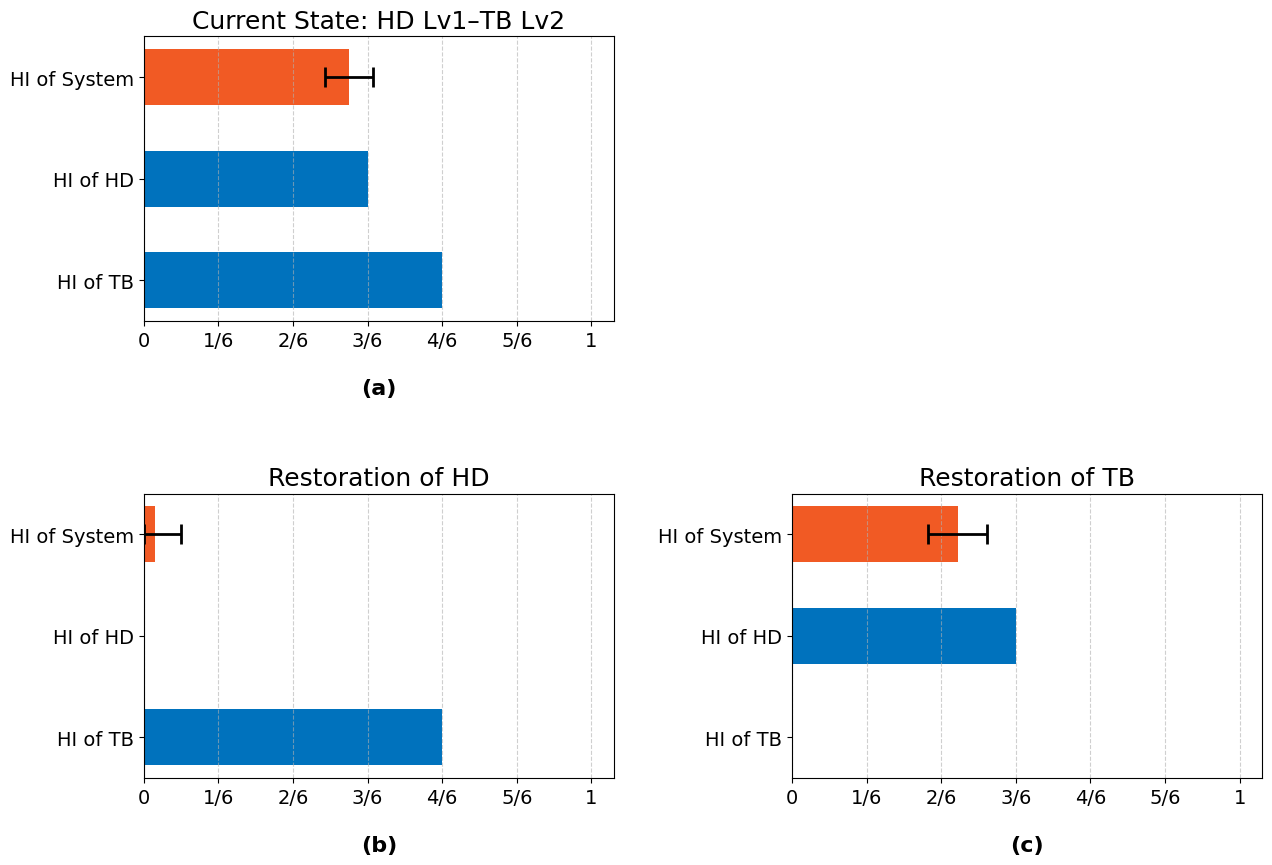

In [ ]:
# Purpose: tick formatter that renders common fractions (0, 1/6, ..., 1).
# Input: value, position.
# Output: returned labels[nearest] if abs(nearest - value) < 1e-06 else ''.
# Used in: robot fault diagnosis.
def fraction_tick(value, position):
    labels = {
        0: "0",
        1 / 6: "1/6",
        2 / 6: "2/6",
        3 / 6: "3/6",
        4 / 6: "4/6",
        5 / 6: "5/6",
        1: "1",
    }
    nearest = min(labels, key=lambda t: abs(t - value))
    return labels[nearest] if abs(nearest - value) < 1e-6 else ""

# Purpose: horizontal bar chart with a system-hi error bar for one maintenance scenario.
# Input: axis, title, hd_value, tb_value, system_value, lower, upper.
# Output: updated state or displayed result; no return value.
# Used in: robot fault diagnosis.
def plot_health_state(axis, title, hd_value, tb_value, system_value, lower, upper):
    values = [system_value, hd_value, tb_value]
    axis.barh(
        np.arange(3), values, color=["#F15A24", "#0072BD", "#0072BD"], height=0.55
    )
    xerr = np.array([[system_value - lower], [upper - system_value]])
    axis.errorbar(
        system_value,
        0,
        xerr=xerr,
        fmt="none",
        ecolor="black",
        elinewidth=2,
        capsize=7,
        capthick=2,
    )
    axis.set_yticks(np.arange(3), ["HI of System", "HI of HD", "HI of TB"])
    axis.invert_yaxis()
    axis.set_xlim(0, 1.05); axis.set_xticks(np.arange(0, 1.01, 1 / 6))
    axis.xaxis.set_major_formatter(FuncFormatter(fraction_tick))
    axis.grid(True, axis="x", linestyle="--", alpha=0.6); axis.set_title(title)

figure, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_health_state(
    axes[0, 0],
    f"Current State: {condition_name}",
    current_hd_hi,
    current_tb_hi,
    current_sys_hi,
    cur_lo,
    cur_hi,
)
plot_health_state(
    axes[1, 0], "Restoration of HD", 0.0, current_tb_hi, sys_after_hd, hd_lo, hd_hi
)
plot_health_state(
    axes[1, 1], "Restoration of TB", current_hd_hi, 0.0, sys_after_tb, tb_lo, tb_hi
)
axes[0, 1].axis("off")
for axis, label in zip([axes[0, 0], axes[1, 0], axes[1, 1]], ["(a)", "(b)", "(c)"]):
    axis.text(
        0.5,
        -0.20,
        label,
        transform=axis.transAxes,
        ha="center",
        va="top",
        fontweight="bold",
    )
plt.tight_layout(h_pad=2.8, w_pad=2.0); plt.show()

# Bayesian network for robot

- **BN 1**: HD, TB → features. Structure learning reduces 224 candidate features to 5 via BIC. CPDs are Gaussian.
- **BN 2**: HD, TB → S (system HI). Uses a Bayesian quadratic regression on the 55 GPR measurements.

## Functions for Bayesian networks

In [ ]:
# Purpose: BIC for a Gaussian mixture with one mean/std per group.
# Input: x - feature values; groups - group label for each value.
# Output: scalar BIC score; smaller values indicate a better model.
# Used in: Bayesian network for robot.
def gaussian_bic(x, groups):
    log_likelihood = sum(
        np.sum(
            norm.logpdf(
                x[groups == g],
                loc=np.mean(x[groups == g]),
                scale=max(np.std(x[groups == g]), 1e-10),
            )
        )
        for g in np.unique(groups)
    )
    n_params = 2 * len(np.unique(groups))
    return -2 * log_likelihood + n_params * np.log(len(x))

# Purpose: map (parent_set, hd, tb) to a scalar group key.
# Input: parent_set - none, HD, TB, or HD+TB; hd, tb - severity levels.
# Output: integer group key used to look up Gaussian CPD parameters.
# Used in: Bayesian network for robot.
def parent_key(parent_set, hd, tb):
    if parent_set == "HD":
        return int(hd)
    if parent_set == "TB":
        return int(tb)
    if parent_set == "HD+TB":
        return int(10 * hd + tb)
    return 0

# Purpose: compute p(state | features) for each row of feature_matrix.
# Input: feature_matrix - samples by selected features; uses trained state_prior, valid_states, and
# feature_cpds.
# Output: samples by valid states array, with each row summing to one.
# Used in: Bayesian network for robot.
def joint_posterior(feature_matrix):
    log_prob = np.tile(np.log(state_prior), (len(feature_matrix), 1))
    for state_id, (hd, tb) in enumerate(valid_states):
        for col, (parent_set, parameters) in enumerate(feature_cpds):
            mean, std = parameters[parent_key(parent_set, hd, tb)]
            log_prob[:, state_id] += norm.logpdf(feature_matrix[:, col], mean, std)
    log_prob -= logsumexp(log_prob, axis=1, keepdims=True)
    return np.exp(log_prob)

# Purpose: quadratic basis [1, hd, tb, hd*tb, hd^2, tb^2] for system BN.
# Input: hd, tb - corresponding HD and TB health-index values.
# Output: matrix with columns [1, hd, tb, hd*tb, hd^2, tb^2].
# Used in: Bayesian network for robot.
def system_basis(hd, tb):
    hd, tb = np.asarray(hd), np.asarray(tb)
    return np.column_stack(
        [
            np.ones(np.size(hd)),
            hd.ravel(),
            tb.ravel(),
            (hd * tb).ravel(),
            (hd**2).ravel(),
            (tb**2).ravel(),
        ]
    )

## Load Features_robot.mat and split data.

In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import loadmat
from scipy.special import logsumexp
from scipy.stats import invgamma, norm, spearmanr
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, log_loss
from sklearn.model_selection import train_test_split

ROBOT_ROOT = DATA_ROOT / "Robot"

feature_file = ROBOT_ROOT / "Features_robot.mat"

feature_data = loadmat(feature_file)
feat_robot = np.asarray(feature_data["feat_robot"], dtype=float)
labseg = np.asarray(feature_data["labseg"], dtype=int)

# Convert the feature names loaded from the MAT file to Python strings.
feature_names = []
for value in np.asarray(feature_data["feat_name"]).reshape(-1):
    if isinstance(value, np.ndarray):
        value = value.squeeze()
        feature_names.append(
            "".join(value.tolist()) if value.dtype.kind in "US" else str(value.tolist())
        )
    else:
        feature_names.append(str(value))

tb_level = labseg[:, 0].astype(int)
hd_level = labseg[:, 2].astype(int)
joint_level = 10 * hd_level + tb_level

if feat_robot.shape != (1100, 224) or labseg.shape[0] != 1100:
    raise ValueError(f"Unexpected data shapes: {feat_robot.shape}, {labseg.shape}")

print(
    "Features:",
    feat_robot.shape,
    " | HD levels:",
    np.unique(hd_level),
    " | TB levels:",
    np.unique(tb_level),
)

TEST_SIZE = 0.30
RANDOM_STATE = 42

train_idx, test_idx = train_test_split(
    np.arange(len(feat_robot)),
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=joint_level,
)
print(f"Training: {len(train_idx)}  |  Test: {len(test_idx)}")
assert len(train_idx) == 770 and len(test_idx) == 330

Features: (1100, 224)  | HD levels: [0 1 2]  | TB levels: [0 1 2 3]
Training: 770  |  Test: 330


## Feature selection by structure learning

For each feature, BIC determines whether its best parent set is None / HD only / TB only / HD+TB. Features with Delta BIC > threshold and low mutual correlation are selected.

In [ ]:
DELTA_BIC_MIN = 10
CORR_LIMIT = 0.8
MAX_FEATURES = 5

x_train = feat_robot[train_idx]
hd_train = hd_level[train_idx]
tb_train = tb_level[train_idx]

parent_models = {
    "None": np.zeros(len(train_idx), dtype=int),
    "HD": hd_train,
    "TB": tb_train,
    "HD+TB": 10 * hd_train + tb_train,
}

# Bic-based structure learning for all 224 features
results = []
for j in range(feat_robot.shape[1]):
    bic = {
        name: gaussian_bic(x_train[:, j], groups)
        for name, groups in parent_models.items()
    }
    best_parent = min(bic, key=bic.get)
    results.append([j, feature_names[j], best_parent, bic["None"] - bic[best_parent]])

structure_table = pd.DataFrame(
    results, columns=["Index", "Feature", "Parent set", "Delta BIC"]
).sort_values("Delta BIC", ascending=False)

# Select strongly related and nonredundant features
selected_indices = []
for _, row in structure_table.iterrows():
    j = int(row["Index"])
    if row["Delta BIC"] <= DELTA_BIC_MIN:
        continue
    redundant = any(
        np.isfinite(spearmanr(x_train[:, j], x_train[:, k]).statistic)
        and abs(spearmanr(x_train[:, j], x_train[:, k]).statistic) >= CORR_LIMIT
        for k in selected_indices
    )
    if not redundant:
        selected_indices.append(j)
    if len(selected_indices) >= MAX_FEATURES:
        break

selected_structure = (
    structure_table.set_index("Index").loc[selected_indices].reset_index()
)
print(
    f"Features with Delta BIC > {DELTA_BIC_MIN}: "
    f'{(structure_table["Delta BIC"] > DELTA_BIC_MIN).sum()}'
)
print(f"Final selected: {len(selected_indices)}")
display(selected_structure)

Features with Delta BIC > 10: 221
Final selected: 5


,Index,Feature,Parent set,Delta BIC
0,109,Cur-W7-SE,HD+TB,5058.675616
1,95,Cur-W6-SE,HD+TB,4691.205037
2,67,Cur-W4-SE,HD+TB,3065.267688
3,4,Cur-W0-KUR,HD+TB,2966.740493
4,25,Cur-W1-SE,HD+TB,2921.609447


### Option: use paper-defined features

The five features from the paper can be used directly instead of running the automatic selection above.

In [ ]:
# Five features selected in the paper (uncomment to override automatic selection)
# selected_features = ['Cur-W1-STD', 'Cur-W7-MF', 'Cur-W7-Peak(Max)',
# 'Vel-w0-sf', 'vel-w7-sf']
# selected_indices = [list(feature_names).index(name) for name in selected_features]
# selected_structure = pd.DataFrame({
# 'Index': selected_indices, 'feature': selected_features,
# 'Parent set': ['HD+TB'] * Len(selected_features)
# })
# display(selected_structure)

## BN for HD and TB diagnosis

Posterior $P(HD,TB\mid F)$ is calculated for each test sample via the learnt CPDs.

### Estimate BN parameters for HD and TB diagnosis

In [ ]:
# Standardise selected features using the training-data mean and standard deviation
selected_parent_sets = selected_structure["Parent set"].tolist()
train_mean = feat_robot[train_idx][:, selected_indices].mean(axis=0)
train_std = feat_robot[train_idx][:, selected_indices].std(axis=0, ddof=0)
train_std[train_std < 1e-12] = 1.0

x_train = (feat_robot[train_idx][:, selected_indices] - train_mean) / train_std
x_test = (feat_robot[test_idx][:, selected_indices] - train_mean) / train_std

# Estimate prior probabilities of observed hd-tb joint states using add-one smoothing
valid_states = sorted(set(zip(hd_train.tolist(), tb_train.tolist())))
state_to_id = {state: i for i, state in enumerate(valid_states)}
state_train = np.array([state_to_id[(h, t)] for h, t in zip(hd_train, tb_train)])
state_counts = np.bincount(state_train, minlength=len(valid_states))
state_prior = (state_counts + 1.0) / (len(state_train) + len(valid_states))

# Estimate Gaussian CPD parameters for each selected feature
feature_cpds = []
for col, parent_set in enumerate(selected_parent_sets):
    groups = np.array([parent_key(parent_set, h, t) for h, t in zip(hd_train, tb_train)])
    parameters = {}
    for group in np.unique(groups):
        values = x_train[groups == group, col]
        parameters[int(group)] = (
            float(values.mean()),
            max(float(values.std(ddof=0)), 0.05),
        )
    feature_cpds.append((parent_set, parameters))

### Example diagnosis for a sample feature

One feature sample from HD HI = 0.5, TB HI = 2/3 in the test set.

,Component,True HI,Posterior mean,Lower 95%,Upper 95%,Predicted level,Correct
0,HD,0.500,0.500,0.500,0.500,0.500,True
1,TB,0.667,0.625,0.333,0.667,0.667,True


/tmp/ipykernel_2789/422673179.py:63: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout();  plt.show()


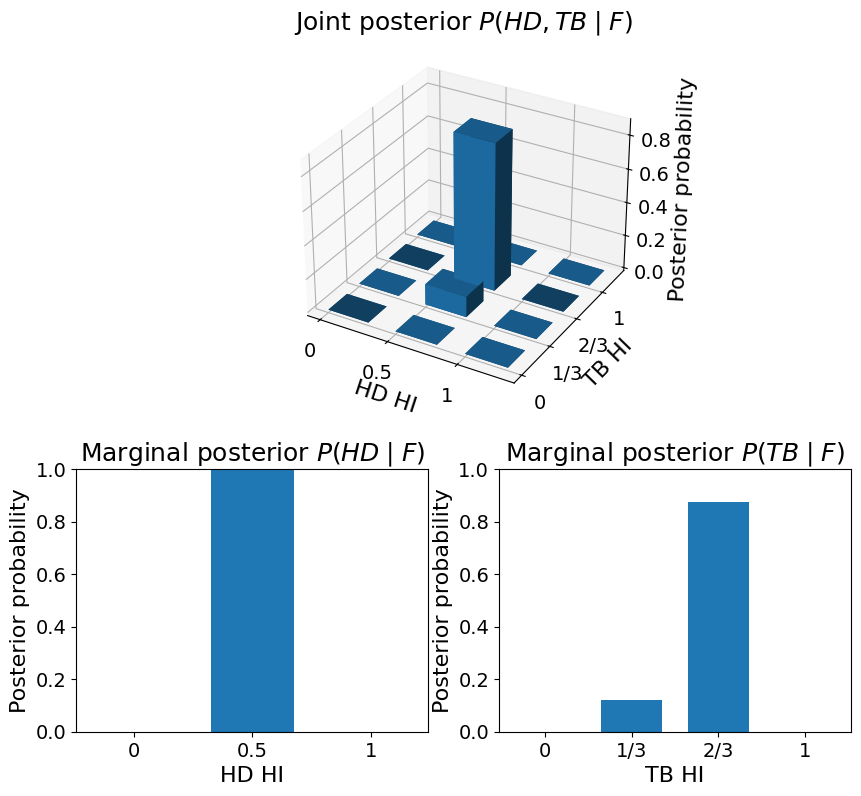

In [ ]:
example_hd_hi = 0.5
example_tb_hi = 2 / 3
candidates = test_idx[
    (hd_level[test_idx] / 2 == example_hd_hi)
    & (tb_level[test_idx] / 3 == example_tb_hi)
]
example_id = candidates[0]

x_example = (feat_robot[[example_id]][:, selected_indices] - train_mean) / train_std
posterior = joint_posterior(x_example)[0]
levels = {"HD": np.array([0, 0.5, 1]), "TB": np.array([0, 1 / 3, 2 / 3, 1])}

rows = []
posterior_probs = {}
for k, (name, values) in enumerate(levels.items()):
    prob = np.array(
        [
            posterior[
                [i for i, state in enumerate(valid_states) if state[k] == j]
            ].sum()
            for j in range(len(values))
        ]
    )
    posterior_probs[name] = prob
    mean = prob @ values
    cdf = np.cumsum(prob)
    predicted = values[np.argmin(np.abs(values - mean))]
    true = example_hd_hi if name == "HD" else example_tb_hi
    rows.append(
        [
            name,
            true,
            mean,
            values[np.searchsorted(cdf, 0.025)],
            values[np.searchsorted(cdf, 0.975)],
            predicted,
            np.isclose(predicted, true),
        ]
    )

display(
    pd.DataFrame(
        rows,
        columns=[
            "Component",
            "True HI",
            "Posterior mean",
            "Lower 95%",
            "Upper 95%",
            "Predicted level",
            "Correct",
        ],
    ).round(3)
)

p_joint = np.zeros((3, 4))
for prob, (hd, tb) in zip(posterior, valid_states):
    p_joint[hd, tb] = prob
p_hd_example = p_joint.sum(axis=1)
p_tb_example = p_joint.sum(axis=0)

fig = plt.figure(figsize=(10, 9))
grid = fig.add_gridspec(2, 2, height_ratios=[1.4, 1])

ax_joint = fig.add_subplot(grid[0, :], projection="3d")
hd_g, tb_g = np.meshgrid(range(3), range(4), indexing="ij")
ax_joint.bar3d(
    hd_g.ravel(), tb_g.ravel(), np.zeros(12), 0.6, 0.6, p_joint.ravel(), shade=True
)
ax_joint.set_xticks(range(3), ["0", "0.5", "1"])
ax_joint.set_yticks(range(4), ["0", "1/3", "2/3", "1"]); ax_joint.set_xlabel("HD HI")
ax_joint.set_ylabel("TB HI"); ax_joint.set_zlabel("Posterior probability")
ax_joint.set_title(r"Joint posterior $P(HD,TB\mid F)$")

ax_hd = fig.add_subplot(grid[1, 0])
ax_hd.bar(range(3), p_hd_example, width=0.7)
ax_hd.set_xticks(range(3), ["0", "0.5", "1"]); ax_hd.set_xlabel("HD HI")
ax_hd.set_ylabel("Posterior probability"); ax_hd.set_ylim(0, 1)
ax_hd.set_title(r"Marginal posterior $P(HD\mid F)$")

ax_tb = fig.add_subplot(grid[1, 1])
ax_tb.bar(range(4), p_tb_example, width=0.7)
ax_tb.set_xticks(range(4), ["0", "1/3", "2/3", "1"]); ax_tb.set_xlabel("TB HI")
ax_tb.set_ylabel("Posterior probability"); ax_tb.set_ylim(0, 1)
ax_tb.set_title(r"Marginal posterior $P(TB\mid F)$")

plt.tight_layout(); plt.show()

### Application to full test set

,Component,Accuracy,Log loss,Test samples
0,HD,1.000000,2.147867e-07,330
1,TB,0.948485,1.640480e-01,330


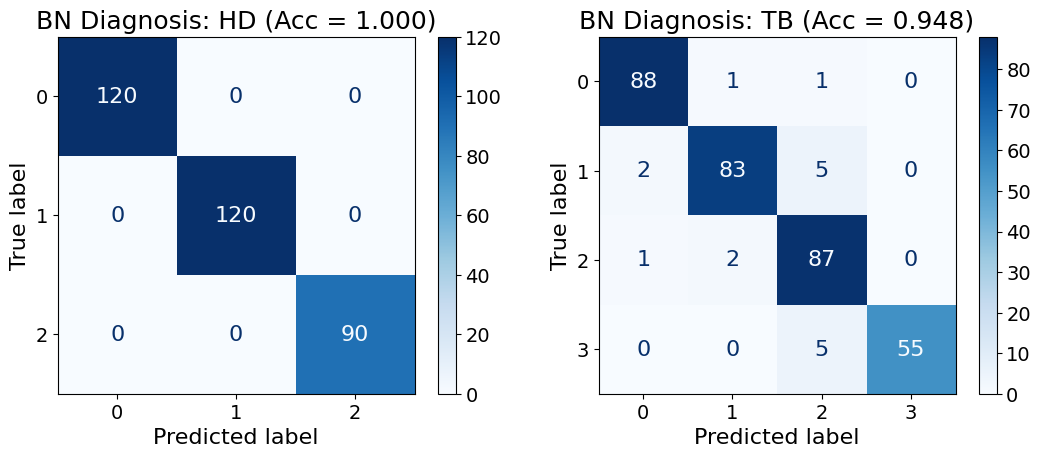

In [ ]:
# Calculate joint hd-tb posterior probabilities for all test samples
posterior_test = joint_posterior(x_test)

# Sum joint probabilities to obtain separate HD and TB severity probabilities
p_hd = np.column_stack(
    [
        posterior_test[
            :, [i for i, state in enumerate(valid_states) if state[0] == lv]
        ].sum(axis=1)
        for lv in range(3)
    ]
)
p_tb = np.column_stack(
    [
        posterior_test[
            :, [i for i, state in enumerate(valid_states) if state[1] == lv]
        ].sum(axis=1)
        for lv in range(4)
    ]
)

# Select the most probable severity level for each component
pred_hd, pred_tb = p_hd.argmax(axis=1), p_tb.argmax(axis=1)

# Evaluate diagnosis accuracy and log loss for HD and TB
metrics_bn1 = pd.DataFrame(
    {
        "Component": ["HD", "TB"],
        "Accuracy": [
            accuracy_score(hd_level[test_idx], pred_hd),
            accuracy_score(tb_level[test_idx], pred_tb),
        ],
        "Log loss": [
            log_loss(hd_level[test_idx], p_hd),
            log_loss(tb_level[test_idx], p_tb),
        ],
        "Test samples": [len(test_idx), len(test_idx)],
    }
)
display(metrics_bn1)

# Plot confusion matrices for HD and TB severity classification
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    hd_level[test_idx], pred_hd, ax=axes[0], cmap="Blues"
)
ConfusionMatrixDisplay.from_predictions(
    tb_level[test_idx], pred_tb, ax=axes[1], cmap="Blues"
)
axes[0].set_title(
    f"BN Diagnosis: HD (Acc = {format_number(metrics_bn1.Accuracy.iloc[0], '.3f')})"
)
axes[1].set_title(
    f"BN Diagnosis: TB (Acc = {format_number(metrics_bn1.Accuracy.iloc[1], '.3f')})"
)
plt.tight_layout(); plt.show()

## BN for S from HD and TB

The 55 measured vibration RMS values are converted to system HI and fitted by a Bayesian quadratic regression with unknown noise variance.

In [ ]:
# Convert measured vibration RMS to system HI
s_gpr = rms_to_system_hi(vibration_rms, rms_min, rms_max)

# Bayesian linear regression with normal-inversegamma prior
design = system_basis(gpr_input[:, 1], gpr_input[:, 0])
p = design.shape[1]
beta0 = np.zeros(p)
prior_cov = np.eye(p) * 100.0
prior_prec = np.linalg.inv(prior_cov)
post_cov = np.linalg.inv(prior_prec + design.T @ design)
post_beta = post_cov @ (prior_prec @ beta0 + design.T @ s_gpr)
a0, b0 = 2.0, 0.1
a_post = a0 + len(s_gpr) / 2.0
b_post = b0 + 0.5 * (s_gpr @ s_gpr - post_beta @ np.linalg.solve(post_cov, post_beta))

print("BN 2 training measurements:", len(s_gpr))
print("System-HI range:", s_gpr.min(), "to", s_gpr.max())

BN 2 training measurements: 55
System-HI range: 0.0 to 1.0


## Probabilistic maintenance scenarios

The joint posterior from the example diagnosis propagates through BN 2 to obtain a predictive distribution over S for three scenarios.

,Variable,Mean,Lower 95%,Upper 95%
0,System HI,0.421,0.341,0.481
1,HD HI,0.500,0.500,0.500
2,TB HI,0.626,0.333,0.667


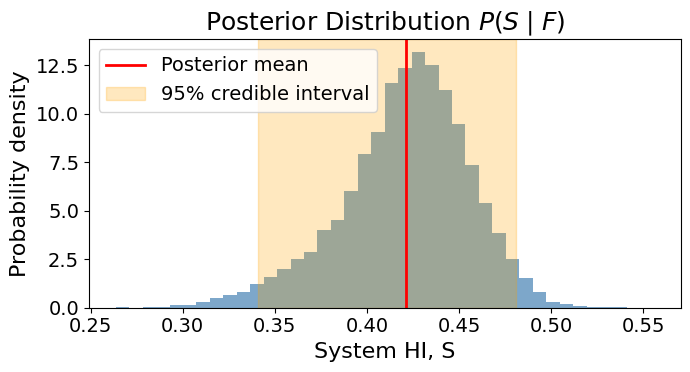

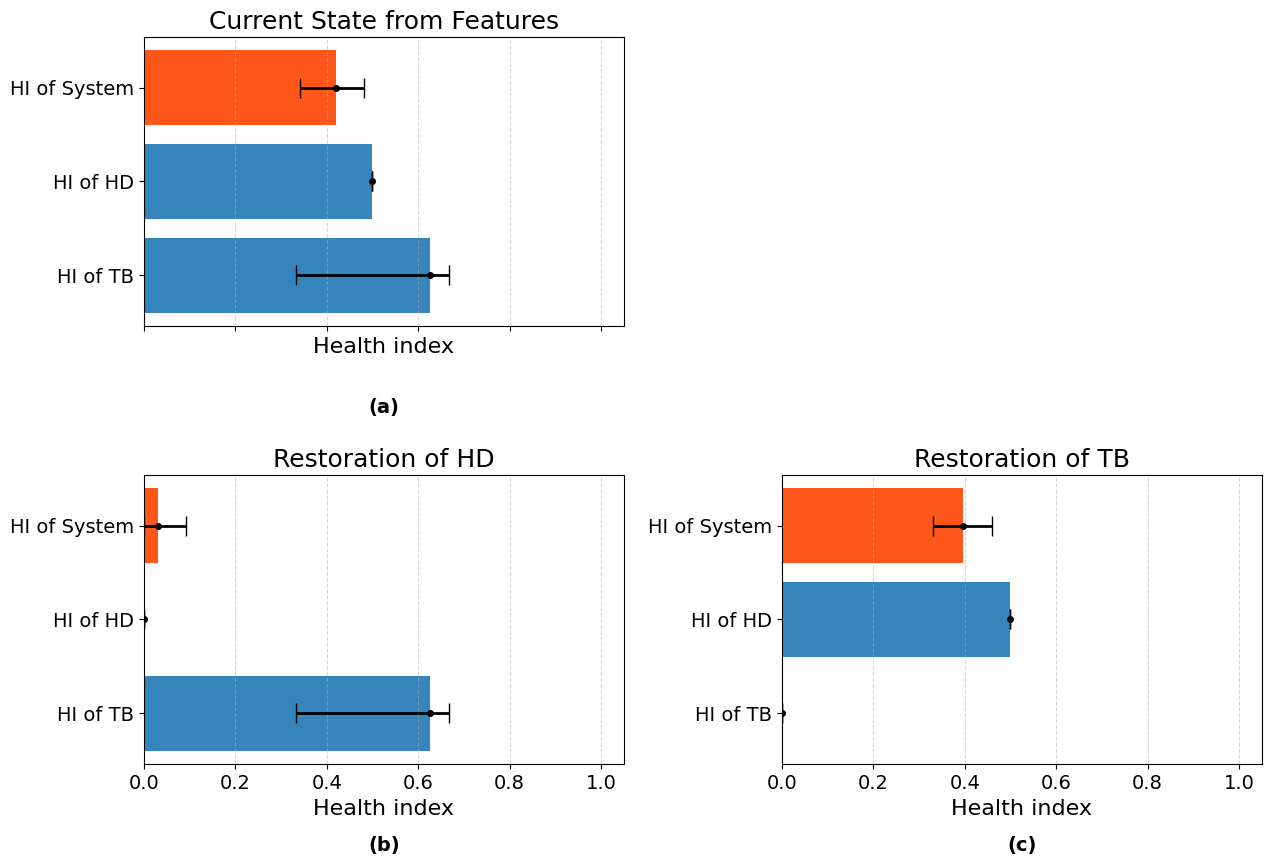

In [ ]:
N_POSTERIOR_DRAWS = 20000
rng_bn = np.random.default_rng(RANDOM_STATE)

# Draw (HD, TB) jointly from BN 1 posterior of the previous example diagnosis
state_draws = np.array(valid_states)[
    rng_bn.choice(len(valid_states), N_POSTERIOR_DRAWS, p=posterior)
]
hd_draws, tb_draws = state_draws[:, 0] / 2, state_draws[:, 1] / 3

# Draw BN 2 response surface coefficients and noise variance
sigma2_draws = invgamma.rvs(
    a=a_post, scale=b_post, size=N_POSTERIOR_DRAWS, random_state=rng_bn
)
beta_draws = np.array(
    [rng_bn.multivariate_normal(post_beta, s2 * post_cov) for s2 in sigma2_draws]
)

scenarios = {
    "Current State from Features": (hd_draws, tb_draws),
    "Restoration of HD": (np.zeros(N_POSTERIOR_DRAWS), tb_draws),
    "Restoration of TB": (hd_draws, np.zeros(N_POSTERIOR_DRAWS)),
}

results = {}
for name, (hd, tb) in scenarios.items():
    draws = np.clip(np.sum(beta_draws * system_basis(hd, tb), axis=1), 0, 1)
    results[name] = {
        "hd": hd.mean(),
        "hd_lower": np.quantile(hd, 0.025),
        "hd_upper": np.quantile(hd, 0.975),
        "tb": tb.mean(),
        "tb_lower": np.quantile(tb, 0.025),
        "tb_upper": np.quantile(tb, 0.975),
        "mean": draws.mean(),
        "lower": np.quantile(draws, 0.025),
        "upper": np.quantile(draws, 0.975),
        "draws": draws,
    }

current = results["Current State from Features"]
display(
    pd.DataFrame(
        {
            "Variable": ["System HI", "HD HI", "TB HI"],
            "Mean": [current["mean"], hd_draws.mean(), tb_draws.mean()],
            "Lower 95%": [
                current["lower"],
                np.quantile(hd_draws, 0.025),
                np.quantile(tb_draws, 0.025),
            ],
            "Upper 95%": [
                current["upper"],
                np.quantile(hd_draws, 0.975),
                np.quantile(tb_draws, 0.975),
            ],
        }
    ).round(3)
)

plt.figure(figsize=(7, 4))
plt.hist(current["draws"], bins=40, density=True, color="steelblue", alpha=0.7)
plt.axvline(current["mean"], color="red", linewidth=2, label="Posterior mean")
plt.axvspan(
    current["lower"],
    current["upper"],
    color="orange",
    alpha=0.25,
    label="95% credible interval",
)
plt.xlabel("System HI, S"); plt.ylabel("Probability density")
plt.title(r"Posterior Distribution $P(S\mid F)$"); plt.legend(); plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
plot_axes = [axes[0, 0], axes[1, 0], axes[1, 1]]
for ax, label, (title, result) in zip(plot_axes, ["(a)", "(b)", "(c)"], results.items()):
    values = np.array([result["tb"], result["hd"], result["mean"]])
    lower = np.array([result["tb_lower"], result["hd_lower"], result["lower"]])
    upper = np.array([result["tb_upper"], result["hd_upper"], result["upper"]])
    ax.barh(
        ["HI of TB", "HI of HD", "HI of System"],
        values,
        color=["tab:blue", "tab:blue", "orangered"],
        alpha=0.9,
    )
    ax.errorbar(
        values,
        range(3),
        xerr=[values - lower, upper - values],
        fmt="o",
        color="black",
        markersize=4,
        capsize=7,
        linewidth=2,
    )
    ax.set_title(title); ax.set_xlabel("Health index"); ax.set_xlim(0, 1.05)
    ax.set_xticks(np.arange(0, 1.01, 0.2)); ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.text(
        0.5,
        -0.25,
        label,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=14,
        fontweight="bold",
    )
axes[0, 1].axis("off")
plt.tight_layout(); plt.show()

# Kalman filter

## Constant voltage

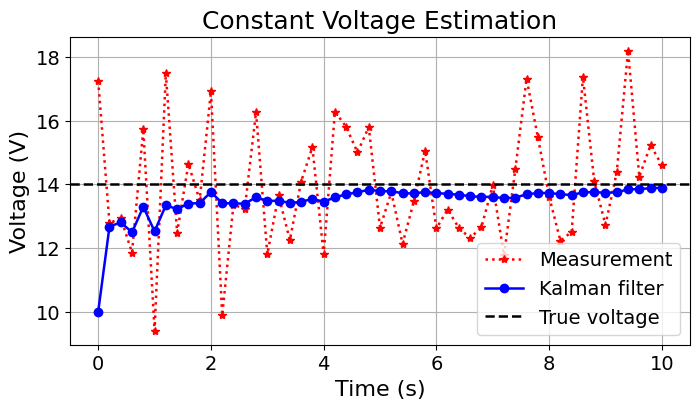

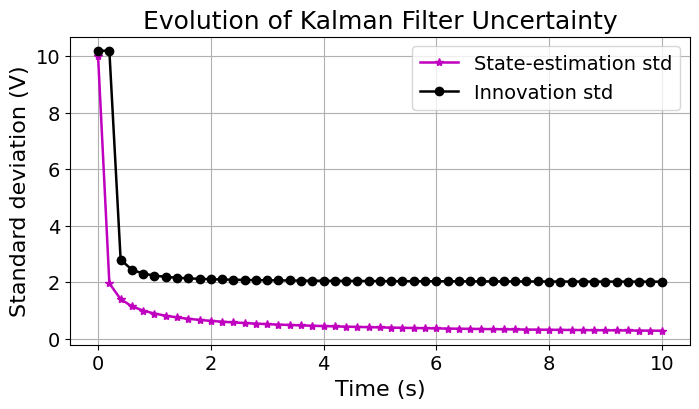

Final estimate = 13.893 V


In [ ]:
# Imports for this section
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation, PillowWriter

np.random.seed(1)

t = np.arange(0, 10.2, 0.2)
true_voltage = 14
s_kf = 2
z = true_voltage + s_kf * np.random.randn(len(t))
Q_kf = 0
R_kf = s_kf**2

xhat = np.zeros(len(t))
P_kf = np.zeros(len(t))
S_kf = np.zeros(len(t))
xhat[0] = 10
P_kf[0] = 100
S_kf[0] = P_kf[0] + R_kf

for k in range(1, len(t)):
    P0 = P_kf[k - 1] + Q_kf
    S_kf[k] = P0 + R_kf
    K = P0 / S_kf[k]
    xhat[k] = xhat[k - 1] + K * (z[k] - xhat[k - 1])
    P_kf[k] = (1 - K) * P0

plt.figure(figsize=(8, 4))
plt.plot(t, z, "r:*", label="Measurement")
plt.plot(t, xhat, "bo-", label="Kalman filter")
plt.axhline(true_voltage, color="k", ls="--", label="True voltage")
plt.xlabel("Time (s)"); plt.ylabel("Voltage (V)")
plt.title("Constant Voltage Estimation"); plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t, np.sqrt(P_kf), "m*-", label="State-estimation std")
plt.plot(t, np.sqrt(S_kf), "ko-", label="Innovation std")
plt.xlabel("Time (s)"); plt.ylabel("Standard deviation (V)")
plt.title("Evolution of Kalman Filter Uncertainty"); plt.legend(); plt.grid(); plt.show()
print(f"Final estimate = {format_number(xhat[-1], '.3f')} V")

## Linear varying voltage

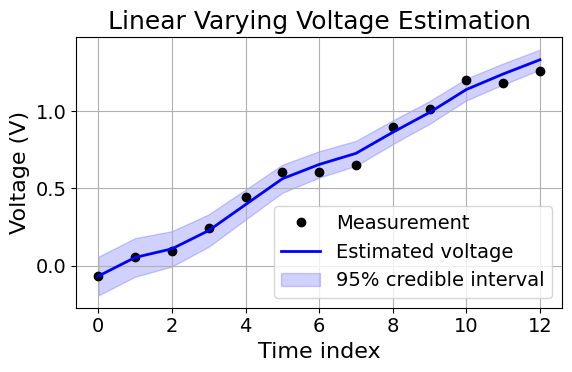

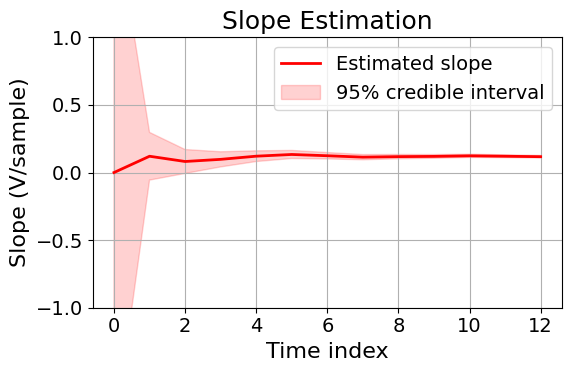

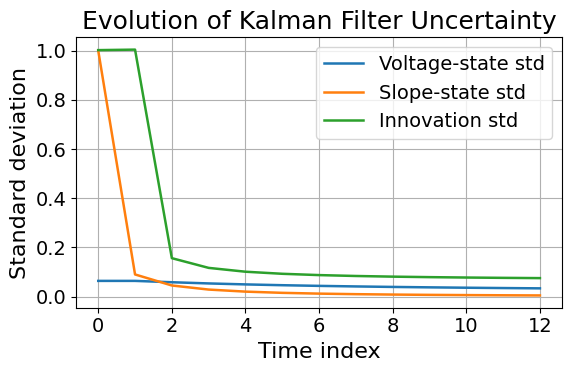

Final voltage estimate = 1.3332 V
Final slope estimate   = 0.1171 V/sample


In [ ]:
z = np.array(
    [
        -0.0679,
        0.0538,
        0.0959,
        0.2435,
        0.4423,
        0.6050,
        0.6080,
        0.6542,
        0.9005,
        1.0126,
        1.2034,
        1.1855,
        1.2586,
    ]
)
t = np.arange(len(z))
n = len(z)

# KF model: state X = [voltage x, slope b]
F = np.array([[1, 1.0], [0, 1]])  # dt = 1
H = np.array([[1, 0]])
Q = np.zeros((2, 2))
# Q = np.eye(2)*0.01
R = 0.064**2
X = np.array([0.0, 0.0])
P = np.eye(2)

Xhat = np.zeros((n, 2))
Phat = np.zeros((n, 2, 2))
S_kf = np.zeros(n)
I2 = np.eye(2)

for k in range(n):
    if k > 0:
        X = F @ X
        P = F @ P @ F.T + Q
    S_kf[k] = (H @ P @ H.T)[0, 0] + R
    K = P @ H.T / S_kf[k]
    X = X + K[:, 0] * (z[k] - (H @ X)[0])
    P = (I2 - K @ H) @ P
    Xhat[k] = X
    Phat[k] = P

std_x = np.sqrt(Phat[:, 0, 0])
std_b = np.sqrt(Phat[:, 1, 1])
ci = 1.96

plt.figure(figsize=(6, 4))
plt.plot(t, z, "ko", label="Measurement")
plt.plot(t, Xhat[:, 0], "b-", lw=2, label="Estimated voltage")
plt.fill_between(
    t,
    Xhat[:, 0] - ci * std_x,
    Xhat[:, 0] + ci * std_x,
    color="b",
    alpha=0.18,
    label="95% credible interval",
)
plt.xlabel("Time index"); plt.ylabel("Voltage (V)")
plt.title("Linear Varying Voltage Estimation"); plt.grid(); plt.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
plt.plot(t, Xhat[:, 1], "r-", lw=2, label="Estimated slope")
plt.fill_between(
    t,
    Xhat[:, 1] - ci * std_b,
    Xhat[:, 1] + ci * std_b,
    color="r",
    alpha=0.18,
    label="95% credible interval",
)
plt.xlabel("Time index"); plt.ylabel("Slope (V/sample)"); plt.ylim(-1, 1)
plt.title("Slope Estimation"); plt.grid(); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
plt.plot(t, std_x, label="Voltage-state std")
plt.plot(t, std_b, label="Slope-state std")
plt.plot(t, np.sqrt(S_kf), label="Innovation std")
plt.xlabel("Time index"); plt.ylabel("Standard deviation")
plt.title("Evolution of Kalman Filter Uncertainty"); plt.grid(); plt.legend()
plt.tight_layout(); plt.show()

print(f"Final voltage estimate = {format_number(Xhat[-1, 0], '.4f')} V")
print(f"Final slope estimate   = {format_number(Xhat[-1, 1], '.4f')} V/sample")

# Optional: save animation to Drive
make_animation = False
gif_path = PROJECT_ROOT / "kalman_linear_voltage.gif"

if make_animation:
    fig, ax_anim = plt.subplots(1, 2, figsize=(12, 4.5))

    # Purpose: update one animation frame.
    # Input: frame.
    # Output: updated state or displayed result; no return value.
    def update(frame):
        k = frame + 1
        for a in ax_anim:
            a.clear()
        ax_anim[0].plot(t[:k], z[:k], "ko", label="Measurement")
        ax_anim[0].plot(t[:k], Xhat[:k, 0], "b-", lw=2, label="Estimated voltage")
        ax_anim[0].fill_between(
            t[:k],
            Xhat[:k, 0] - ci * std_x[:k],
            Xhat[:k, 0] + ci * std_x[:k],
            color="b",
            alpha=0.18,
            label="95% credible interval",
        )
        ax_anim[0].set(
            xlim=(t[0], t[-1]),
            ylim=(-0.3, 1.6),
            xlabel="Time index",
            ylabel="Voltage",
            title="Linear Varying Voltage Estimation",
        )
        ax_anim[0].grid()
        ax_anim[0].legend(loc="upper left")
        ax_anim[1].plot(t[:k], Xhat[:k, 1], "r-", lw=2, label="Estimated slope")
        ax_anim[1].fill_between(
            t[:k],
            Xhat[:k, 1] - ci * std_b[:k],
            Xhat[:k, 1] + ci * std_b[:k],
            color="r",
            alpha=0.18,
            label="95% credible interval",
        )
        ax_anim[1].set(
            xlim=(t[0], t[-1]),
            ylim=(-0.5, 0.5),
            xlabel="Time index",
            ylabel="Slope (V/sample)",
            title="Slope Estimation",
        )
        ax_anim[1].grid()
        ax_anim[1].legend(loc="upper right")
        fig.tight_layout()

    FuncAnimation(fig, update, frames=n, interval=700).save(
        gif_path, writer=PillowWriter(fps=1.5)
    )
    plt.close(fig)
    print(f"Animation saved to: {gif_path}")

## Damping coef estimation by EKF

### Simulation data for EKF

Simple first-order motor model: $J\dot{x} + cx = u$, where $x$ is speed, $c$ is the damping coefficient (fault parameter).

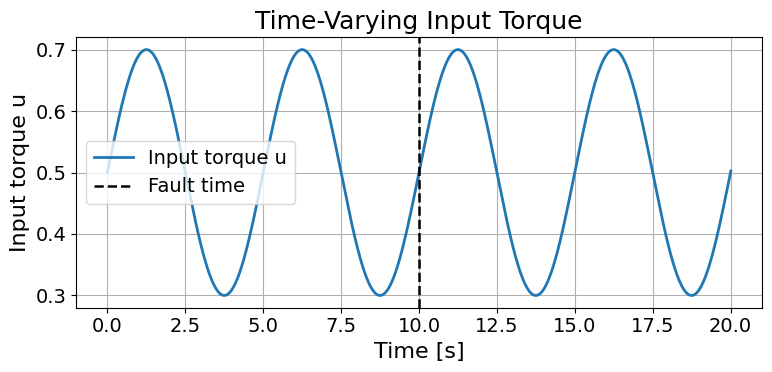

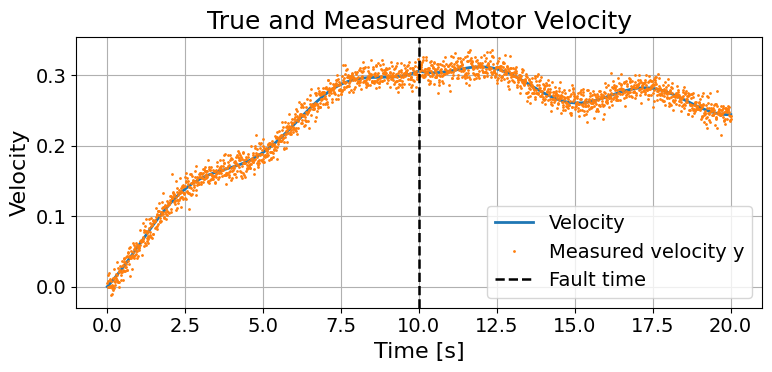

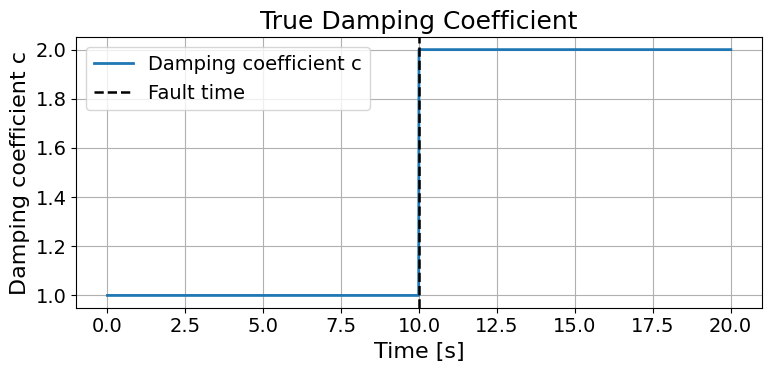

In [ ]:
# First-order motor model: j dx/dt + c x = u
# State to estimate: [x, c]; c steps from 1.0 to 2.0 at t = fault_time
dt_ekf = 0.01
J_ekf = 10
fault_time = 10
t_ekf = np.arange(0, 20 + dt_ekf, dt_ekf)
u_ekf = 0.5 + 0.2 * np.sin(2 * np.pi * 0.2 * t_ekf)
c_true = np.where(t_ekf < fault_time, 1.0, 2.0)

x_true = np.zeros(len(t_ekf))
for k in range(len(t_ekf) - 1):
    x_true[k + 1] = x_true[k] + dt_ekf * (u_ekf[k] - c_true[k] * x_true[k]) / J_ekf

np.random.seed(42)
s_meas = 0.01
y_meas = x_true + s_meas * np.random.randn(len(t_ekf))

for data, ylabel, title in [
    (u_ekf, "Input torque u", "Time-Varying Input Torque"),
    (x_true, "Velocity", "True and Measured Motor Velocity"),
    (c_true, "Damping coefficient c", "True Damping Coefficient"),
]:
    plt.figure(figsize=(8, 4))
    plt.plot(t_ekf, data, lw=2, label=ylabel)
    if ylabel == "Velocity":
        plt.plot(t_ekf, y_meas, ".", ms=2, label="Measured velocity y")
    plt.axvline(fault_time, color="k", ls="--", label="Fault time")
    plt.xlabel("Time [s]"); plt.ylabel(ylabel); plt.title(title); plt.grid(); plt.legend()
    plt.tight_layout(); plt.show()

### Estimation using EKF

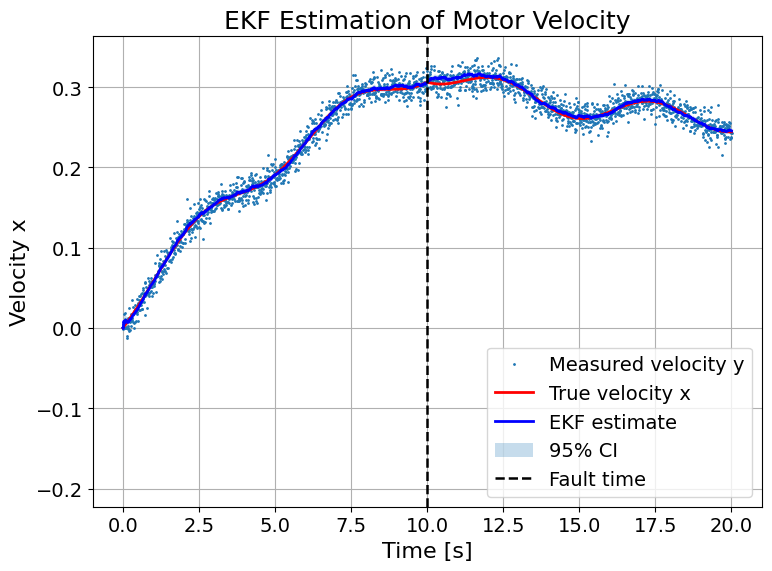

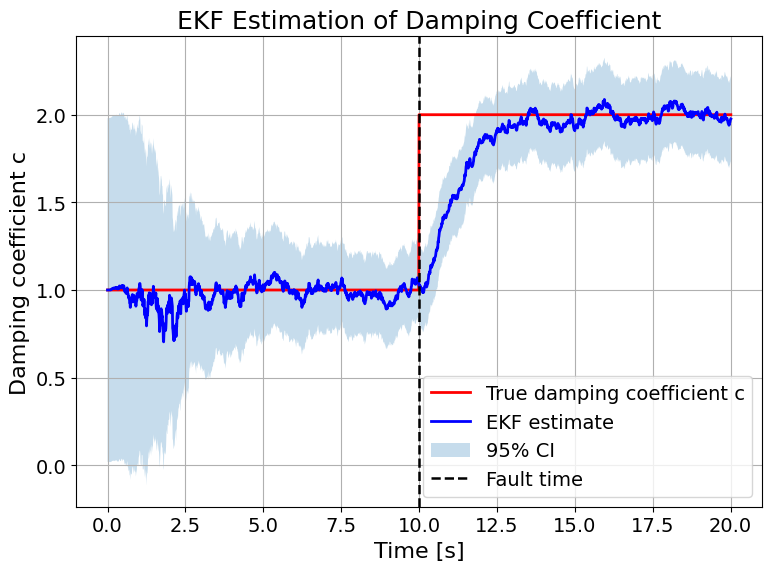

In [ ]:
# EKF state: x = [velocity x, damping coefficient c]
n_ekf = len(t_ekf)
Xhat_ekf = np.zeros((2, n_ekf))
P_ekf = np.zeros((2, 2, n_ekf))
Xhat_ekf[:, 0] = [0, 1]
P_ekf[:, :, 0] = np.diag([0.1**2, 0.5**2])
Q_ekf = np.diag([1e-7, 1e-4])
R_ekf = s_meas**2
H_ekf = np.array([[1.0, 0.0]])
I2_ekf = np.eye(2)

for k in range(1, n_ekf):
    x_val, c_val = Xhat_ekf[:, k - 1]
    X0 = np.array([x_val + dt_ekf * (u_ekf[k - 1] - c_val * x_val) / J_ekf, c_val])
    F = np.array([[1 - dt_ekf * c_val / J_ekf, -dt_ekf * x_val / J_ekf], [0, 1]])
    P0 = F @ P_ekf[:, :, k - 1] @ F.T + Q_ekf
    S_k = (H_ekf @ P0 @ H_ekf.T)[0, 0] + R_ekf
    K = P0 @ H_ekf.T / S_k
    Xhat_ekf[:, k] = X0 + K[:, 0] * (y_meas[k] - X0[0])
    P_ekf[:, :, k] = (I2_ekf - K @ H_ekf) @ P0

std_ekf = np.sqrt(np.stack([P_ekf[0, 0], P_ekf[1, 1]]))

# Purpose: plot ekf result.
# Input: j, true_vals, ylabel, title, show_meas.
# Output: updated state or displayed result; no return value.
# Used in: Kalman filter.
def plot_ekf_result(j, true_vals, ylabel, title, show_meas=False):
    plt.figure(figsize=(8, 6))
    if show_meas:
        plt.plot(t_ekf, y_meas, ".", ms=2, label="Measured velocity y")
    plt.plot(t_ekf, true_vals, "r-", lw=2, label=f"True {ylabel.lower()}")
    plt.plot(t_ekf, Xhat_ekf[j], "b-", lw=2, label="EKF estimate")
    plt.fill_between(
        t_ekf,
        Xhat_ekf[j] - 1.96 * std_ekf[j],
        Xhat_ekf[j] + 1.96 * std_ekf[j],
        alpha=0.25,
        label="95% CI",
    )
    plt.axvline(fault_time, color="k", ls="--", label="Fault time")
    plt.xlabel("Time [s]"); plt.ylabel(ylabel); plt.title(title); plt.grid(); plt.legend()
    plt.tight_layout(); plt.show()

plot_ekf_result(
    0, x_true, "Velocity x", "EKF Estimation of Motor Velocity", show_meas=True
)
plot_ekf_result(
    1, c_true, "Damping coefficient c", "EKF Estimation of Damping Coefficient"
)

# PMDC load-torque estimation by EKF

Identify the fixed motor parameters and estimate time-varying load torque $T_L$ using an extended Kalman filter applied to real PMDC motor data.

## Functions

In [ ]:
# Purpose: return PMDC test arrays for one PWM and load combination.
# Input: pwm, load.
# Output: list of repeated-test arrays, each containing measured signal columns.
# Used in: PMDC load-torque estimation by EKF.
def get_tests(pwm, load):
    value = data[f"pwm{pwm}_load{load}"]
    return list(value) if value.dtype == object or value.ndim == 3 else [value]

# Purpose: construct PMDC regression inputs and load-torque targets.
# Input: pwms, loads, test_ids, excluded_ids.
# Output: regression matrix, target vector, and number of tests.
# Used in: PMDC load-torque estimation by EKF.
def regression_data(pwms, loads, test_ids=None, excluded_ids=None):
    x_all, y_all, n_tests = [], [], 0
    excluded_ids = set(excluded_ids or [])

    for pwm in pwms:
        for load in loads:
            tests = get_tests(pwm, load)
            ids = test_ids or range(1, len(tests) + 1)

            for test_id in ids:
                if test_id > len(tests) or test_id in excluded_ids:
                    continue

                test = tests[test_id - 1]
                torque = true_torque[load]
                start = np.flatnonzero(test[:, 2] > 5)[0]
                test = test[start:]

                dt_m = np.median(np.diff(test[:, 0]))
                speed = savgol_filter(test[:, 2], 11, 3)
                accel = savgol_filter(test[:, 2], 11, 3, deriv=1, delta=dt_m)

                # J*accel + b*speed - k_t*current = -t_l
                x_all.append(np.column_stack([accel, speed, -test[:, 1]]))
                y_all.append(np.full(len(test), -torque))
                n_tests += 1

    return np.vstack(x_all), np.concatenate(y_all), n_tests

# Purpose: estimate PMDC speed and external load torque with an EKF.
# Input: test.
# Output: returned (time - time[0], history).
# Used in: PMDC load-torque estimation by EKF.
def ekf_pmdc(test):

    start = np.flatnonzero(test[:, 2] > 5)[0]
    time, current, measured_speed = test[start:, :3].T
    state = np.array([measured_speed[0], 0.0])
    covariance = P0_pm.copy()
    history = np.empty((len(time), 2))
    history[0] = state
    H_pm = np.array([[1.0, 0.0]])

    for index, dt_step in enumerate(np.diff(time)):
        step = dt_step / substeps
        for _ in range(substeps):
            speed, torque = state
            numerator = k_T_pm * current[index] - b_pm * speed - torque
            state += step * np.array([numerator / J_pm, 0.0])
            F_pm = np.array([[-b_pm / J_pm, -1 / J_pm], [0.0, 0.0]])
            A_pm = np.eye(2) + step * F_pm
            covariance = A_pm @ covariance @ A_pm.T + Q_pm * step
        innovation = measured_speed[index + 1] - float(H_pm @ state)
        S_pm = float((H_pm @ covariance @ H_pm.T)[0, 0] + R_pm)
        K_pm = covariance @ H_pm.T / S_pm
        state += K_pm[:, 0] * innovation
        I_KH = np.eye(2) - K_pm @ H_pm
        covariance = I_KH @ covariance @ I_KH.T + K_pm * R_pm @ K_pm.T
        history[index + 1] = state

    return time - time[0], history

## Data loading

In [ ]:
# Set the PWM levels and loads for parameter identification
cal_pwms = [80, 90, 100]
cal_loads = [0, 1, 2, 3, 4]
cal_test_ids = list(range(1, 9))  # First eight tests per condition

# Select the PWM (%) for EKF plots: uncomment one assignment only
test_pwm = 50
# test_pwm = 40
# test_pwm = 60
# test_pwm = 70
# test_pwm = 80
# test_pwm = 90
# test_pwm = 100

# Set the loads and their test numbers for EKF plots
test_loads = [0, 1, 2, 3, 4]
test_ids = [7] * 5
# test_ids = [7, 7, 7, 7, 9]
# Check the displayed test counts before selecting each test number

# Imports for this section
import matplotlib.pyplot as plt
import time
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from scipy.io import loadmat
from scipy.signal import savgol_filter

data_file = DATA_ROOT / "Motor_PMDC" / "PMDC_MotorA.mat"
data = loadmat(data_file, simplify_cells=True)

counts = pd.DataFrame(
    [
        [
            len(get_tests(pwm, load)) if f"pwm{pwm}_load{load}" in data else 0
            for load in range(5)
        ]
        for pwm in range(40, 101, 10)
    ],
    index=range(40, 101, 10),
    columns=range(5),
)
counts.index.name = "PWM (%)"
counts.columns.name = "Load (kgf)"
display(counts.T)
print(f"Total tests for Motor A: {counts.to_numpy().sum()}")

# Data selection (test ids start from 1)
# Fixed-parameter identification: 3 PWM levels x 5 loads x 8 tests = 120 tests

# EKF load-torque estimation at 50% PWM

true_torque = np.array([0, 0.059820565, 0.119641130, 0.179461695, 0.239282260])

PWM (%),40,50,60,70,80,90,100
Load (kgf),,,,,,,
0,10,10,10,10,10,10,10
1,11,11,11,11,10,10,11
2,11,11,11,11,10,11,11
3,10,10,10,10,10,10,10
4,2,10,10,10,10,10,10


Total tests for Motor A: 353


## 1. Model parameter identification

### Identification of model parameters

In [ ]:
from scipy.optimize import lsq_linear

x_cal, y_cal, n_cal = regression_data(cal_pwms, cal_loads, cal_test_ids)

# Scale columns before nonnegative constrained least squares.
scale = np.linalg.norm(x_cal, axis=0)
if np.any(scale == 0):
    raise ValueError("A regression column has zero norm.")
x_scaled = x_cal / scale
result = lsq_linear(x_scaled, y_cal, bounds=(0, np.inf))
if not result.success:
    raise RuntimeError(result.message)

J_pm, b_pm, k_T_pm = result.x / scale

print(f"Identification tests = {n_cal}")
print(f"J   = {J_pm:.6e} kg m^2")
print(f"b   = {b_pm:.6e} N m s/rad")
print(f"k_T = {k_T_pm:.6e} N m/A")
print(f"Condition number = {np.linalg.cond(x_scaled):.3e}")

Identification tests = 120
J   = 1.438163e-04 kg m^2
b   = 3.369819e-04 N m s/rad
k_T = 3.935539e-02 N m/A
Condition number = 2.633e+00


### Validation of identified parameters

In [ ]:
parameters = np.array([J_pm, b_pm, k_T_pm])

# Overall identification and validation performance
for name, ids, excluded in [
    ("Identification", cal_test_ids, None),
    ("Validation", None, cal_test_ids),
]:
    x, y, n = regression_data(cal_pwms, cal_loads, ids, excluded)
    residual = x @ parameters - y
    rmse = np.sqrt(np.mean(residual**2))
    r2 = 1 - np.sum(residual**2) / np.sum((y - y.mean()) ** 2)
    print(
        f"{name:14s}: tests = {n:3d}, RMSE = {format_number(rmse, '.5f')} N m, R² ="
        f" {format_number(r2, '.3f')}"
    )

# Validation performance by load level
parameters = np.array([J_pm, b_pm, k_T_pm])
torque_range = np.ptp(true_torque[cal_loads])

# Evaluate torque errors on identification and held-out validation data.
for name, ids, excluded in [
    ("Identification", cal_test_ids, None),
    ("Validation", None, cal_test_ids),
]:
    x, y, n = regression_data(cal_pwms, cal_loads, ids, excluded)
    residual = x @ parameters - y
    rmse = np.sqrt(np.mean(residual**2))
    nrmse = 100 * rmse / torque_range
    print(
        f"{name}: tests = {n}, RMSE = {format_number(rmse, '.5f')} N m, NRMSE ="
        f" {format_number(nrmse, '.1f')}%"
    )

Identification: tests = 120, RMSE = 0.03483 N m, R² = 0.845
Validation    : tests =  33, RMSE = 0.03469 N m, R² = 0.836
Identification: tests = 120, RMSE = 0.03483 N m, NRMSE = 14.6%
Validation: tests = 33, RMSE = 0.03469 N m, NRMSE = 14.5%


## 2. Estimate speed & torque by EKF

### EKF estimation

In [ ]:
P0_pm = np.diag([1.0, 0.5**2])
Q_pm = np.diag(
    [10.0, 1e-10]
)  # Allow speed-model uncertainty; keep load torque constant.
R_pm = 0.01
substeps = 5

# Run EKF for all available tests at each PWM and load.
all_results_pmdc = {
    (pwm, load): [ekf_pmdc(test) for test in get_tests(pwm, load)]
    for pwm in range(40, 101, 10)
    for load in test_loads
    if f"pwm{pwm}_load{load}" in data
}

# Select test ids for the speed and torque time-response plots.
selected_tests = [
    get_tests(test_pwm, load)[test_id - 1]
    for load, test_id in zip(test_loads, test_ids)
]
results_pmdc = [
    all_results_pmdc[test_pwm, load][test_id - 1]
    for load, test_id in zip(test_loads, test_ids)
]

/tmp/ipykernel_3138/969956748.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  innovation = measured_speed[index + 1] - float(H_pm @ state)


### Plot estimated speed

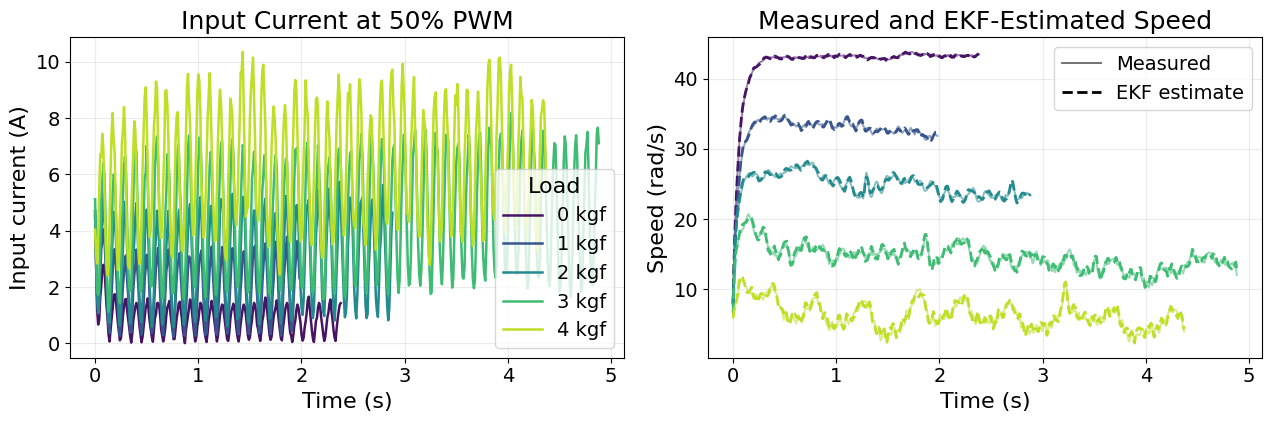

In [ ]:
# Plot input PWM & estimated speeds.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = plt.cm.viridis(np.linspace(0.05, 0.90, len(test_loads)))

for load, test, (time_r, history), color in zip(
    test_loads, selected_tests, results_pmdc, colors
):
    start = np.flatnonzero(test[:, 2] > 5)[0]
    time, current, measured_speed = test[start:, :3].T
    time = time - time[0]
    axes[0].plot(time, current, color=color, label=f"{load} kgf")
    axes[1].plot(time, measured_speed, color=color, lw=1.4, alpha=0.55)
    axes[1].plot(time_r, history[:, 0], color=color, ls="--", lw=2.0)

axes[0].set(
    xlabel="Time (s)", ylabel="Input current (A)", title="Input Current at 50% PWM"
)
axes[0].legend(title="Load"); axes[0].grid(alpha=0.25)
axes[1].set(
    xlabel="Time (s)", ylabel="Speed (rad/s)", title="Measured and EKF-Estimated Speed"
)
axes[1].legend(
    handles=[
        Line2D([0], [0], color="black", lw=1.4, alpha=0.55, label="Measured"),
        Line2D([0], [0], color="black", lw=2.0, ls="--", label="EKF estimate"),
    ]
)
axes[1].grid(alpha=0.25); plt.tight_layout(); plt.show()

### Plot estimated torque

PWM: 50% | Torque unit: N m
Load  True T_L  Mean T_L  STD T_L  Error (%)  Test ID  EKF T_L
   0     0.000     0.018    0.001        nan        7    0.018
   1     0.060     0.064    0.001        6.8        7    0.063
   2     0.120     0.106    0.004      -11.2        7    0.106
   3     0.179     0.169    0.004       -5.9        7    0.172
   4     0.239     0.237    0.005       -0.8        7    0.245


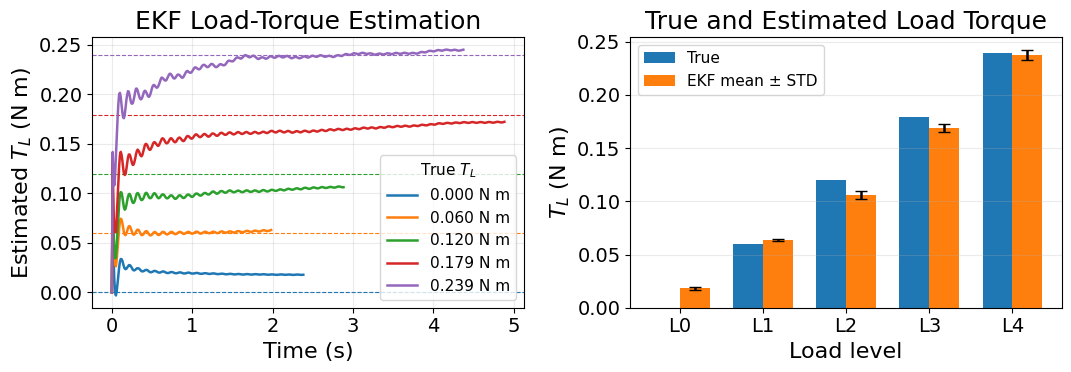

In [ ]:
# Summarize final torque estimates across all tests at the selected PWM.
torque_samples = [
    np.array([history[-1, 1] for _, history in all_results_pmdc[test_pwm, load]])
    for load in test_loads
]
torque_mean = np.array([values.mean() for values in torque_samples])
torque_std = np.array(
    [values.std(ddof=1) if len(values) > 1 else np.nan for values in torque_samples]
)
estimates = np.array([history[-1, 1] for _, history in results_pmdc])

# Print all-test statistics and the selected test's estimate and error.
print(f"PWM: {test_pwm}% | Torque unit: N m")
print("Load  True T_L  Mean T_L  STD T_L  Error (%)  Test ID  EKF T_L")
for load, mean, std, test_id, estimate in zip(
    test_loads, torque_mean, torque_std, test_ids, estimates
):
    truth = true_torque[load]
    error = np.nan if truth == 0 else 100 * (mean - truth) / truth
    print(
        (
            f"{load:4d}"
            f"{format_number(truth, '10.3f')}"
            f"{format_number(mean, '10.3f')}"
            f"{format_number(std, '9.3f')}"
            f"{format_number(error, '11.1f')}"
            f"{test_id:9d}"
            f"{format_number(estimate, '9.3f')}"
        )
    )

# Plot true & estimated load torque.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

x_pos = np.arange(len(test_loads))
width = 0.36

for load, (time_r, history) in zip(test_loads, results_pmdc):
    axes[0].plot(
        time_r, history[:, 1], label=f"{format_number(true_torque[load], '.3f')} N m"
    )
    axes[0].axhline(true_torque[load], color=f"C{load}", ls="--", lw=0.8)
axes[0].set(
    xlabel="Time (s)",
    ylabel=r"Estimated $T_L$ (N m)",
    title="EKF Load-Torque Estimation",
)
axes[0].legend(title=r"True $T_L$", fontsize="x-small", title_fontsize="x-small")
axes[0].grid(alpha=0.25)

axes[1].bar(x_pos - width / 2, true_torque[test_loads], width, label="True")
axes[1].bar(
    x_pos + width / 2,
    torque_mean,
    width,
    yerr=torque_std,
    capsize=4,
    label="EKF mean ± STD",
)
axes[1].set(
    xlabel="Load level",
    ylabel=r"$T_L$ (N m)",
    title="True and Estimated Load Torque",
    xticks=x_pos,
    xticklabels=[f"L{i}" for i in test_loads],
)
axes[1].legend(fontsize="x-small", loc="upper left"); axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout(); plt.show()

# CMU VAH12 SOC estimation

### Data loading and preparation

In [ ]:
# Select a battery cell
test_cell = 'VAH12' # change to VAH01 or 11 if needed.

# Required packages and imports
%pip install -q numpy pandas scipy matplotlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import PchipInterpolator
from scipy.optimize import least_squares

# Google Drive is assumed to be mounted already.
data_dir = DATA_ROOT / "Battery_CMU"

data_path = data_dir / f"{test_cell}.csv"
impedance_path = data_dir / f"{test_cell}_impedance.csv"

if not data_path.exists():
    raise FileNotFoundError(data_path)
if not impedance_path.exists():
    raise FileNotFoundError(impedance_path)

battery = pd.read_csv(data_path)
impedance = pd.read_csv(impedance_path)

battery.columns = battery.columns.str.strip().str.replace(" ", "_", regex=False)
impedance.columns = impedance.columns.str.strip().str.replace(" ", "_", regex=False)

# Reconstruction of sequential cycles
local_cycle = battery["cycleNumber"].astype(int)
segment = battery["Ns"].astype(int)
new_cycle = local_cycle.ne(local_cycle.shift()) | (segment.eq(0) & segment.shift().ne(0))
new_cycle.iloc[0] = True
battery["global_cycle"] = new_cycle.cumsum().astype(int)

# Identification of mission and rpt cycles
cycle_summary = battery.groupby("global_cycle").agg(
    start_time=("time_s", "min"),
    end_time=("time_s", "max"),
    capacity_ah=("QDischarge_mA_h", lambda x: x.max() / 1000),
)
cycle_summary["duration_h"] = (
    cycle_summary["end_time"] - cycle_summary["start_time"]
) / 3600

segment_presence = pd.crosstab(battery["global_cycle"], segment).gt(0)
has_2 = segment_presence.get(2, pd.Series(False, index=segment_presence.index))
has_7 = segment_presence.get(7, pd.Series(False, index=segment_presence.index))
rpt_mask = (
    has_2
    & has_7
    & (cycle_summary["duration_h"] > 5)
    & (cycle_summary["capacity_ah"] > 1.5)
)

rpt_cycles = cycle_summary.index[rpt_mask].to_numpy()
mission_cycles = cycle_summary.index[~rpt_mask].to_numpy()

if len(rpt_cycles) == 0:
    raise ValueError("No RPT cycle was identified")

initial_capacity = cycle_summary.loc[rpt_cycles[0], "capacity_ah"]

print(f"Cell                 = {test_cell}")
print(f"Number of cycles     = {battery.global_cycle.nunique()}")
print(f"Number of RPT cycles = {len(rpt_cycles)}")
print(f"Initial capacity     = {format_number(initial_capacity, '.3f')} Ah")

Cell                 = VAH12
Number of cycles     = 2349
Number of RPT cycles = 47
Initial capacity     = 3.061 Ah


## Model identification

### Initial OCV–SOC curve from the RPT

Initial RPT cycle = 1
OCV table points  = 101
SOC range         = 0.00–1.00
Initial 30 s DCIR = 0.04112–0.03159 Ω


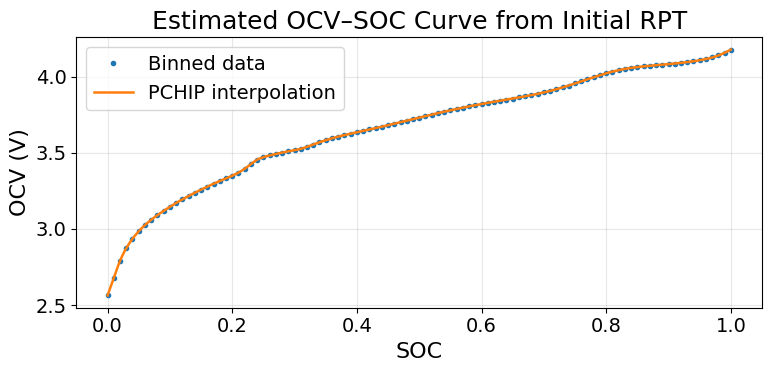

In [ ]:
initial_rpt_cycle = rpt_cycles[0]
rpt = battery[
    (battery["global_cycle"] == initial_rpt_cycle) & battery["I_mA"].between(-800, -400)
].copy()

rpt["soc"] = 1 - rpt["QDischarge_mA_h"] / (1000 * initial_capacity)
rpt["dod"] = 1 - rpt["soc"]

r20 = impedance["20%_30_second"].iloc[0]
r60 = impedance["60%_30_second"].iloc[0]
rpt["resistance"] = np.interp(rpt["dod"], [0.2, 0.6], [r20, r60])
rpt["ocv"] = rpt["Ecell_V"] - rpt["I_mA"] * rpt["resistance"] / 1000
rpt["soc"] = rpt["soc"].clip(0, 1).round(2)

ocv_table = rpt.groupby("soc", as_index=False)["ocv"].median().sort_values("soc")
ocv_function = PchipInterpolator(ocv_table["soc"], ocv_table["ocv"])
d_ocv = ocv_function.derivative()
soc_grid = np.linspace(0, 1, 300)

print(f"Initial RPT cycle = {initial_rpt_cycle}")
print(f"OCV table points  = {len(ocv_table)}")
print(
    "SOC range         ="
    f" {format_number(ocv_table['soc'].min(), '.2f')}–{format_number(ocv_table['soc'].max(), '.2f')}"
)
print(f"Initial 30 s DCIR = {format_number(r20, '.5f')}–{format_number(r60, '.5f')} Ω")

plt.figure(figsize=(8, 4))
plt.plot(ocv_table["soc"], ocv_table["ocv"], "o", markersize=3, label="Binned data")
plt.plot(soc_grid, ocv_function(soc_grid), label="PCHIP interpolation")
plt.xlabel("SOC"); plt.ylabel("OCV (V)")
plt.title("Estimated OCV–SOC Curve from Initial RPT"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Initial Thevenin model parameters

Identification cycle = 2
R0   = 0.021806 Ω
R1   = 0.009628 Ω
C1   = 7800.43 F
Tau1 = 75.10 s
Voltage MAE  = 15.26 mV
Voltage RMSE = 20.95 mV


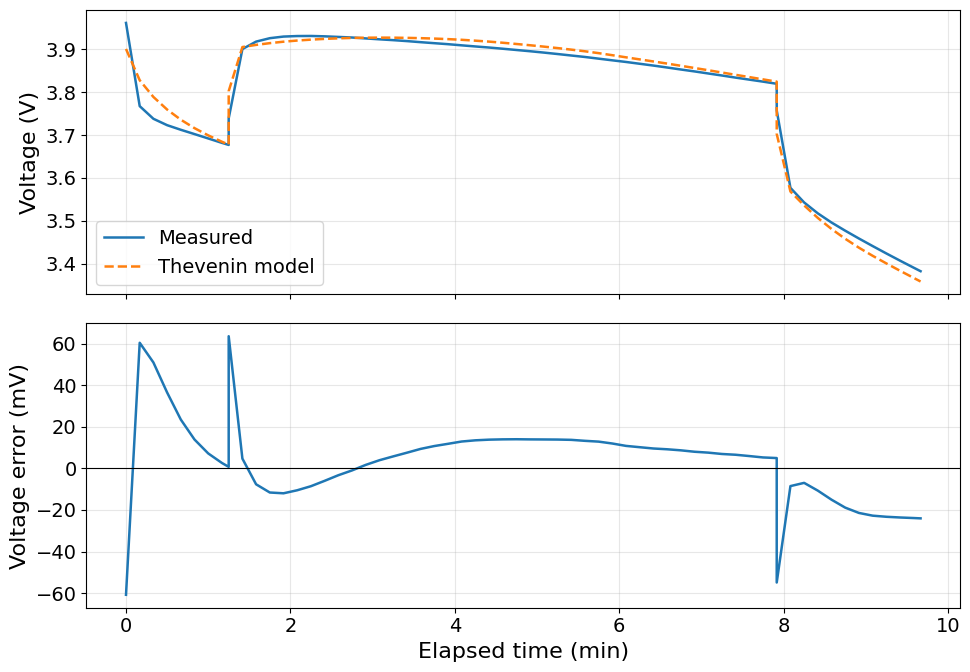

In [ ]:
from scipy.optimize import least_squares

identification_cycle = mission_cycles[mission_cycles > initial_rpt_cycle][0]
identification_data = battery[
    (battery["global_cycle"] == identification_cycle) & battery["Ns"].isin([4, 5, 6])
].sort_values("time_s")

time_ident = identification_data["time_s"].to_numpy()
voltage_ident = identification_data["Ecell_V"].to_numpy()
current_ident = -identification_data["I_mA"].to_numpy() / 1000
dt_ident = np.diff(time_ident, prepend=time_ident[0])
dt_ident[0] = np.median(dt_ident[1:])

# Purpose: simulate Thevenin.
# Input: parameters.
# Output: returned (voltage, soc, v1).
# Used in: CMU VAH12 SOC estimation.
def simulate_thevenin(parameters):
    r0, r1, tau1 = parameters
    soc = np.ones(len(time_ident))
    v1 = np.zeros(len(time_ident))
    voltage = np.zeros(len(time_ident))
    voltage[0] = ocv_function(1.0) - r0 * current_ident[0]

    for k in range(1, len(time_ident)):
        soc[k] = np.clip(
            soc[k - 1] - current_ident[k - 1] * dt_ident[k] / (3600 * initial_capacity),
            0,
            1,
        )
        decay = np.exp(-dt_ident[k] / tau1)
        v1[k] = decay * v1[k - 1] + r1 * (1 - decay) * current_ident[k - 1]
        voltage[k] = ocv_function(soc[k]) - r0 * current_ident[k] - v1[k]

    return voltage, soc, v1

# Purpose: voltage residual.
# Input: parameters.
# Output: returned simulate_thevenin(parameters)[0] - voltage_ident.
# Used in: CMU VAH12 SOC estimation.
def voltage_residual(parameters):
    return simulate_thevenin(parameters)[0] - voltage_ident

r0_initial = np.mean(
    [impedance["20%_1_second"].iloc[0], impedance["60%_1_second"].iloc[0]]
)
r1_initial = np.mean(
    [
        impedance["20%_30_second"].iloc[0] - impedance["20%_1_second"].iloc[0],
        impedance["60%_30_second"].iloc[0] - impedance["60%_1_second"].iloc[0],
    ]
)

result = least_squares(
    voltage_residual,
    x0=[r0_initial, r1_initial, 30],
    bounds=([0.001, 0.001, 1], [0.100, 0.100, 1000]),
)

r0, r1, tau1 = result.x
c1 = tau1 / r1
voltage_model, soc_model, v1_model = simulate_thevenin(result.x)
voltage_error = voltage_model - voltage_ident
voltage_mae = np.mean(np.abs(voltage_error))
voltage_rmse = np.sqrt(np.mean(voltage_error**2))
elapsed_ident = (time_ident - time_ident[0]) / 60

print(f"Identification cycle = {identification_cycle}")
print(f"R0   = {format_number(r0, '.6f')} Ω")
print(f"R1   = {format_number(r1, '.6f')} Ω")
print(f"C1   = {format_number(c1, '.2f')} F")
print(f"Tau1 = {format_number(tau1, '.2f')} s")
print(f"Voltage MAE  = {format_number(1000 * voltage_mae, '.2f')} mV")
print(f"Voltage RMSE = {format_number(1000 * voltage_rmse, '.2f')} mV")

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(elapsed_ident, voltage_ident, label="Measured")
axes[0].plot(elapsed_ident, voltage_model, "--", label="Thevenin model")
axes[0].set_ylabel("Voltage (V)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(elapsed_ident, 1000 * voltage_error)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Elapsed time (min)"); axes[1].set_ylabel("Voltage error (mV)")
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

### Validation of identified Thevenin model

Validation cycle = 3
Voltage MAE  = 14.12 mV
Voltage RMSE = 20.01 mV


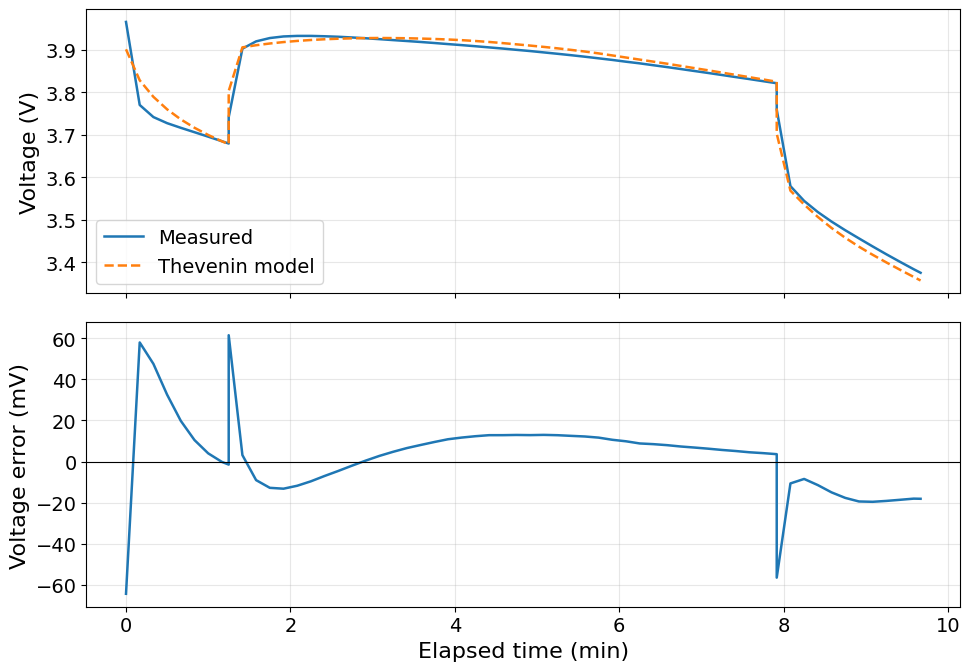

In [ ]:
validation_cycle = mission_cycles[mission_cycles > identification_cycle][0]
validation_data = battery[
    (battery["global_cycle"] == validation_cycle) & battery["Ns"].isin([4, 5, 6])
].sort_values("time_s")

time_val = validation_data["time_s"].to_numpy()
voltage_val = validation_data["Ecell_V"].to_numpy()
current_val = -validation_data["I_mA"].to_numpy() / 1000
dt_val = np.diff(time_val, prepend=time_val[0])
dt_val[0] = np.median(dt_val[1:])

soc_val = np.ones(len(time_val))
v1_val = np.zeros(len(time_val))
voltage_pred = np.zeros(len(time_val))
voltage_pred[0] = ocv_function(1.0) - r0 * current_val[0]

for k in range(1, len(time_val)):
    soc_val[k] = np.clip(
        soc_val[k - 1] - current_val[k - 1] * dt_val[k] / (3600 * initial_capacity),
        0,
        1,
    )
    decay = np.exp(-dt_val[k] / tau1)
    v1_val[k] = decay * v1_val[k - 1] + r1 * (1 - decay) * current_val[k - 1]
    voltage_pred[k] = ocv_function(soc_val[k]) - r0 * current_val[k] - v1_val[k]

voltage_error_val = voltage_pred - voltage_val
voltage_mae_val = np.mean(np.abs(voltage_error_val))
voltage_rmse_val = np.sqrt(np.mean(voltage_error_val**2))
elapsed_val = (time_val - time_val[0]) / 60

print(f"Validation cycle = {validation_cycle}")
print(f"Voltage MAE  = {format_number(1000 * voltage_mae_val, '.2f')} mV")
print(f"Voltage RMSE = {format_number(1000 * voltage_rmse_val, '.2f')} mV")

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(elapsed_val, voltage_val, label="Measured")
axes[0].plot(elapsed_val, voltage_pred, "--", label="Thevenin model")
axes[0].set_ylabel("Voltage (V)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(elapsed_val, 1000 * voltage_error_val)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Elapsed time (min)"); axes[1].set_ylabel("Voltage error (mV)")
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## SOC estimation using EKF

EKF cycle = 4
Coulomb counting RMSE = 10.00%
EKF SOC MAE           = 1.52%
EKF SOC RMSE          = 2.61%


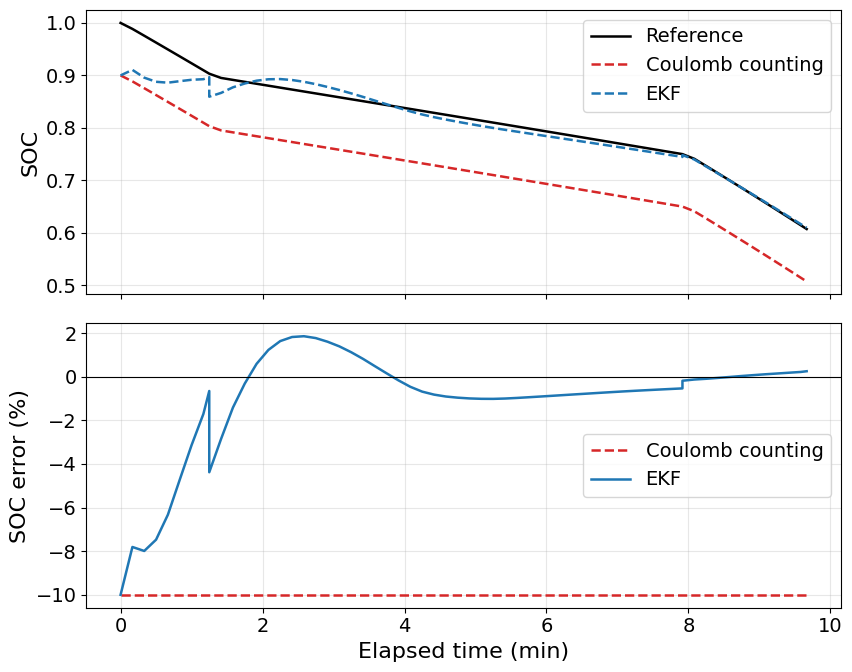

In [ ]:
# Select a mission cycle for SOC estimation
ekf_cycle = 4
# ekf_cycle = mission_cycles[mission_cycles > validation_cycle][0]
ekf_data = battery[
    (battery["global_cycle"] == ekf_cycle) & battery["Ns"].isin([4, 5, 6])
].sort_values("time_s")

t = ekf_data["time_s"].to_numpy()
i = -ekf_data["I_mA"].to_numpy() / 1000
v = ekf_data["Ecell_V"].to_numpy()
dt = np.diff(t, prepend=t[0])
dt[0] = np.median(dt[1:])

n = len(t)
soc_ref = np.ones(n)
soc_est = np.zeros(n)
v1_est = np.zeros(n)
soc_est[0] = 0.9

P = np.diag([0.1**2, 0.05**2])
Qx = np.diag([1e-6, 1e-5])
R = voltage_rmse_val**2

for k in range(1, n):
    soc_ref[k] = soc_ref[k - 1] - i[k - 1] * dt[k] / (3600 * initial_capacity)

    a = np.exp(-dt[k] / tau1)
    soc_pred = np.clip(
        soc_est[k - 1] - i[k - 1] * dt[k] / (3600 * initial_capacity), 0, 1
    )
    v1_pred = a * v1_est[k - 1] + r1 * (1 - a) * i[k - 1]
    x_pred = np.array([soc_pred, v1_pred])

    F = np.diag([1, a])
    P_pred = F @ P @ F.T + Qx

    H = np.array([[np.asarray(d_ocv(soc_pred)).item(), -1]])
    voltage_pred = ocv_function(soc_pred) - r0 * i[k] - v1_pred
    S = (H @ P_pred @ H.T).item() + R
    K = P_pred @ H.T / S

    x = x_pred + K[:, 0] * (v[k] - voltage_pred)
    soc_est[k] = np.clip(x[0], 0, 1)
    v1_est[k] = x[1]

    A = np.eye(2) - K @ H
    P = A @ P_pred @ A.T + K * R @ K.T

soc_cc = soc_ref - 0.1
error_cc = soc_cc - soc_ref
error_ekf = soc_est - soc_ref
elapsed = (t - t[0]) / 60

mae_ekf = 100 * np.mean(np.abs(error_ekf))
rmse_ekf = 100 * np.sqrt(np.mean(error_ekf**2))
rmse_cc = 100 * np.sqrt(np.mean(error_cc**2))

print(f"EKF cycle = {ekf_cycle}")
print(f"Coulomb counting RMSE = {format_number(rmse_cc, '.2f')}%")
print(f"EKF SOC MAE           = {format_number(mae_ekf, '.2f')}%")
print(f"EKF SOC RMSE          = {format_number(rmse_ekf, '.2f')}%")

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axes[0].plot(elapsed, soc_ref, "k", label="Reference")
axes[0].plot(elapsed, soc_cc, "--", color="tab:red", label="Coulomb counting")
axes[0].plot(elapsed, soc_est, "--", color="tab:blue", label="EKF")
axes[0].set_ylabel("SOC"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(elapsed, 100 * error_cc, "--", color="tab:red", label="Coulomb counting")
axes[1].plot(elapsed, 100 * error_ekf, color="tab:blue", label="EKF")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Elapsed time (min)"); axes[1].set_ylabel("SOC error (%)")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()